In [7]:
!apt-get update -qq
!apt-get install -y -qq git-lfs
!git lfs install

import os

if not os.path.exists("/content/pfas_data/.git"):
    !git clone https://huggingface.co/datasets/muhammadzaid270/pfas_data /content/pfas_data

!git -C /content/pfas_data lfs pull

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Git LFS initialized.


USGS Wells: 73 wells | 73 with depth
UCMR: 116 facilities | Contaminated: 5 | Clean: 111
Military sites: 6
Industrial facilities: 1929

--- BUILDING TRAINING MATRIX ---
  Reprojecting to EPSG:32614...
  Joining USGS well attributes...
  Joining military site data...
  Joining industry data...
  Engineering features...
Training matrix: 116 rows | 5 contaminated | 111 clean

--- BUILDING PREDICTION MATRIX ---
  Reprojecting to EPSG:32614...
  Joining military site data...
  Joining industry data...
  Engineering features...
Prediction matrix: 73 wells ready to score
Loading Tier II files...
  Tier II GeoDataFrame: 2,799 facilities
  Enriching training matrix with Tier II features...
  Enriching prediction matrix with Tier II features...
  Tier II enrichment cached.
Extracting cropland.zip...
  Loading matrices for CDL sampling...
  Sampling CDL — training matrix...
  Sampling CDL — prediction matrix...
  CDL enrichment cached.
  Deduplicated: 37 rows → 32 unique landfills
  Enriching tra

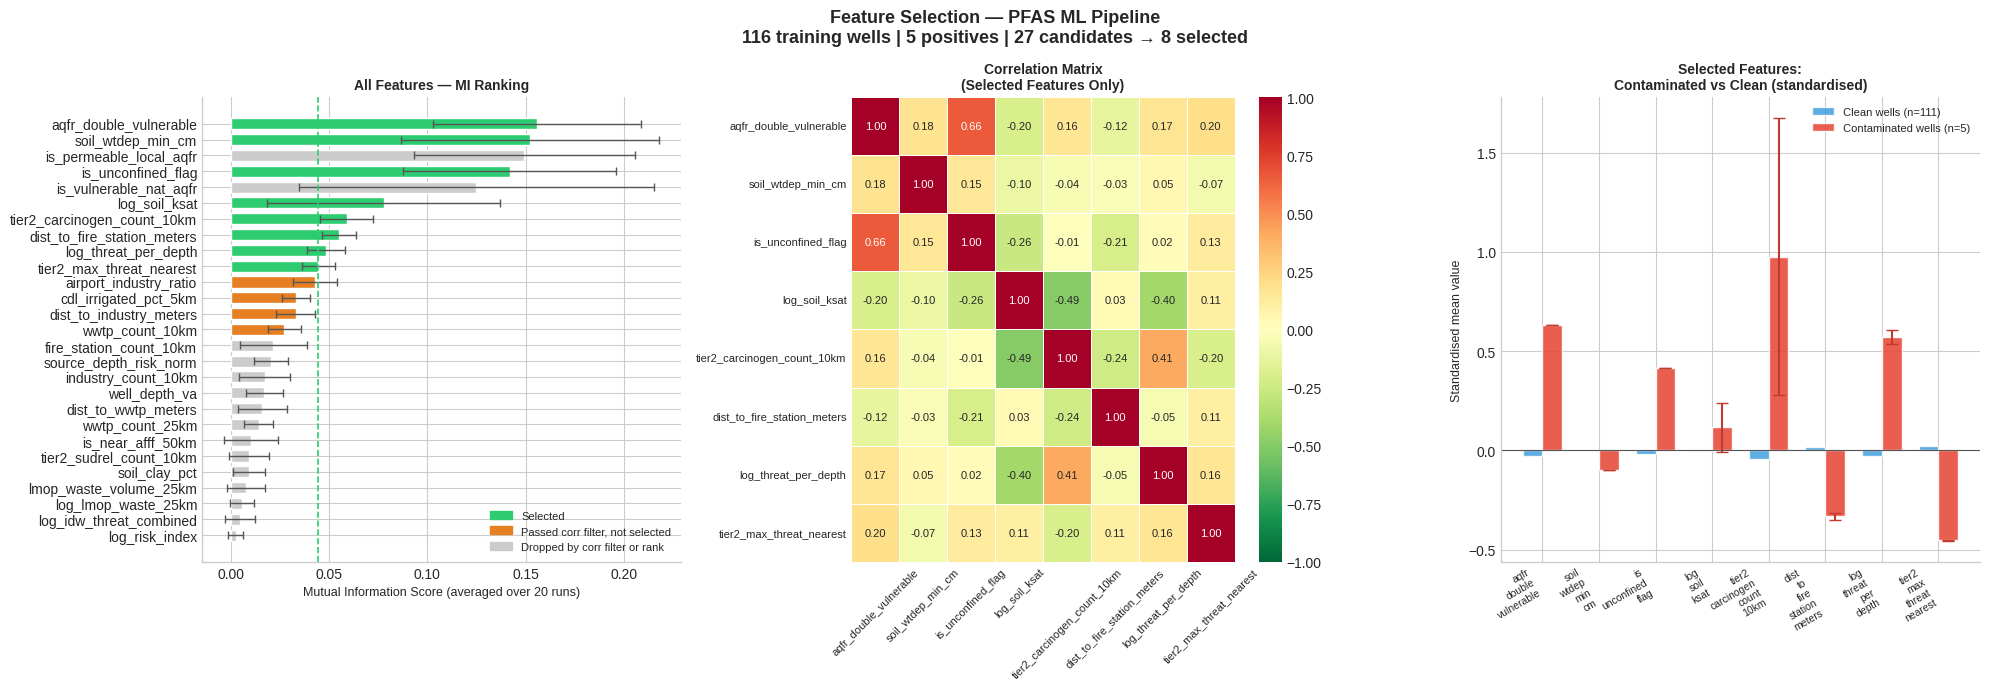


--- ML PIPELINE v9 ---
  Training: 116 rows | Prediction: 73 rows
  Features: 27 | Positives: 5 | Negatives: 111
  Running urban bias audit...
  Urban-biased features flagged: 14
  LOO-CV — Full model...
  LOO-CV [FULL]: median rank 3/189, top5%: 3/5
  LOO-CV — Debiased model...
  LOO-CV [DEBIASED]: median rank 1/189, top5%: 3/5
  Model variant selected: DEBIASED (13 features)
  PR-AUC: 0.3137 | Separation: 2.0x | Best F1: 0.4615
  Saved: Nebraska_Well_Risk_Scores_v9.csv


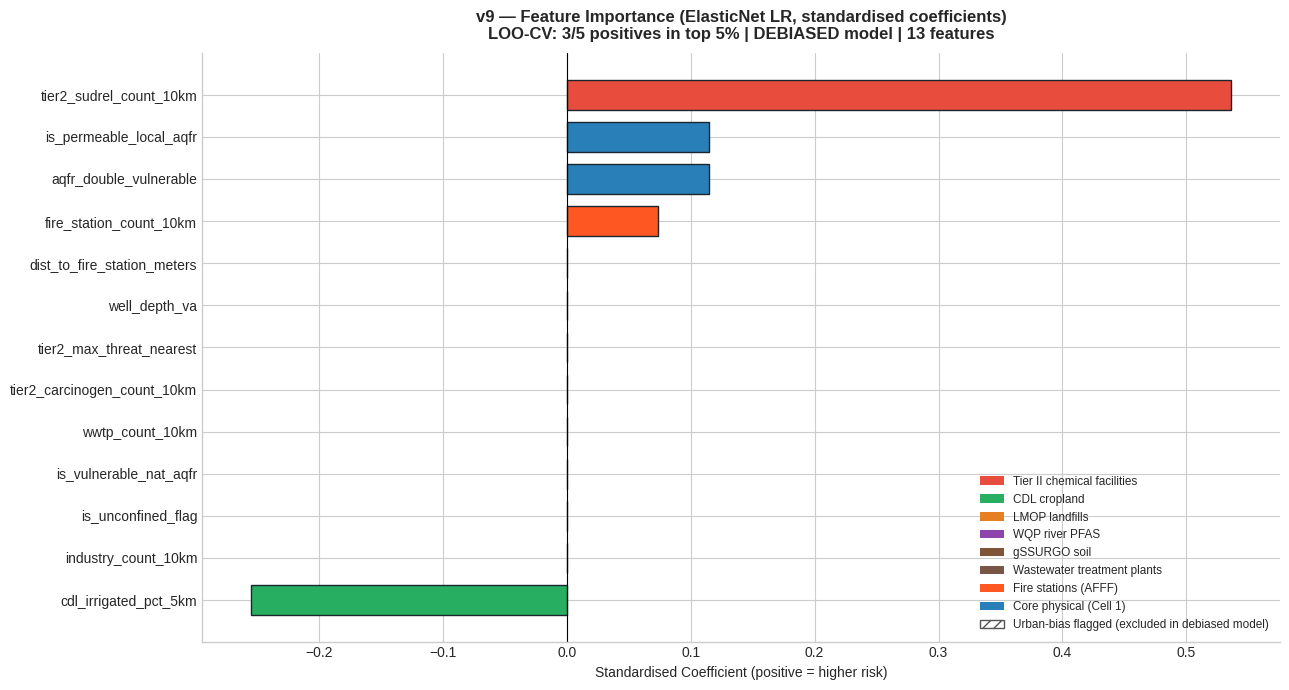

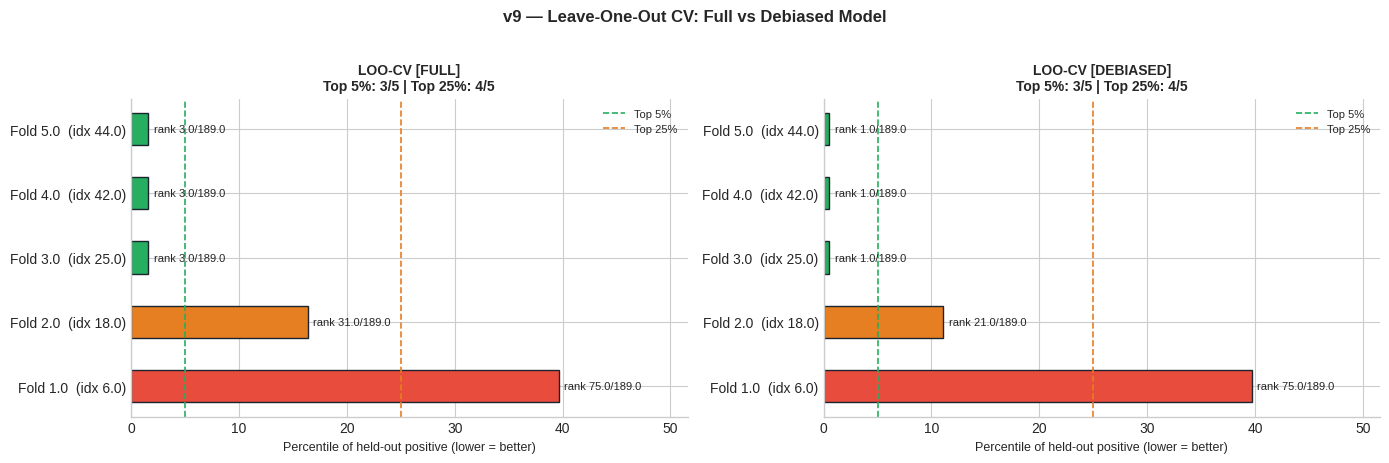

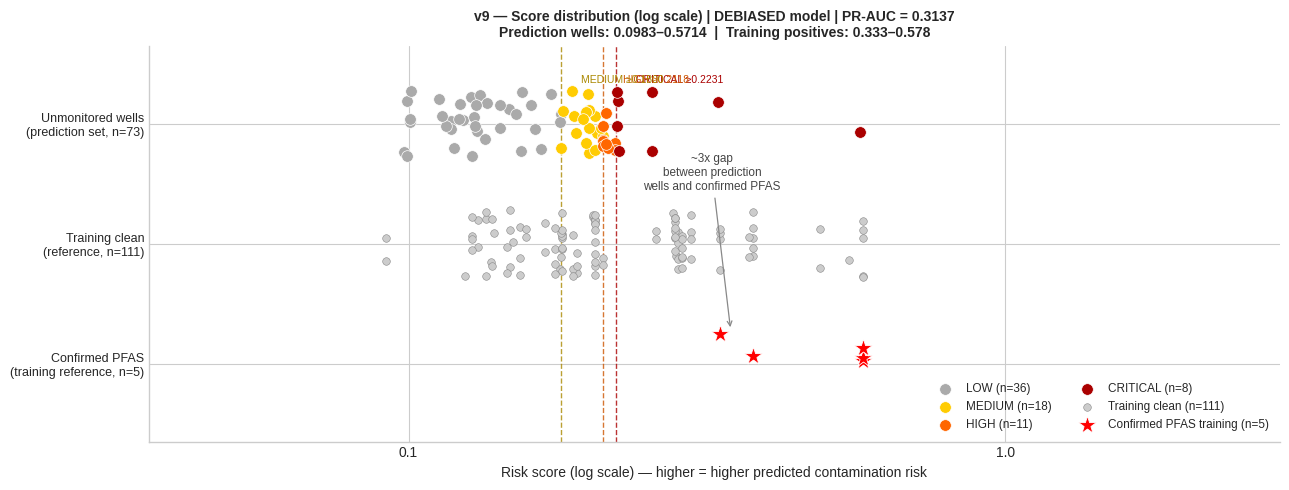

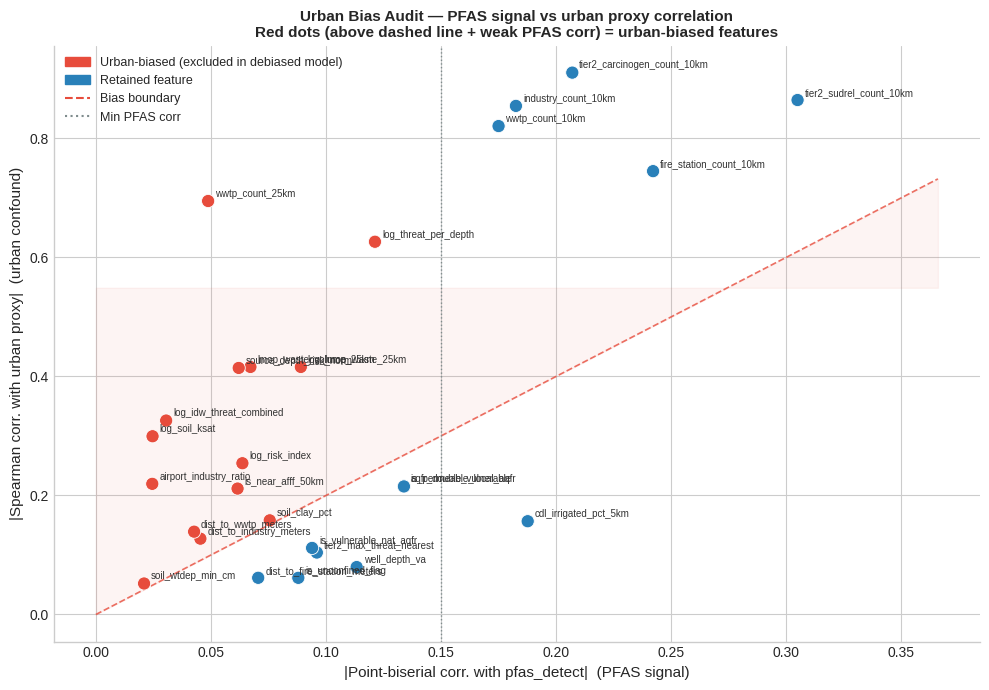

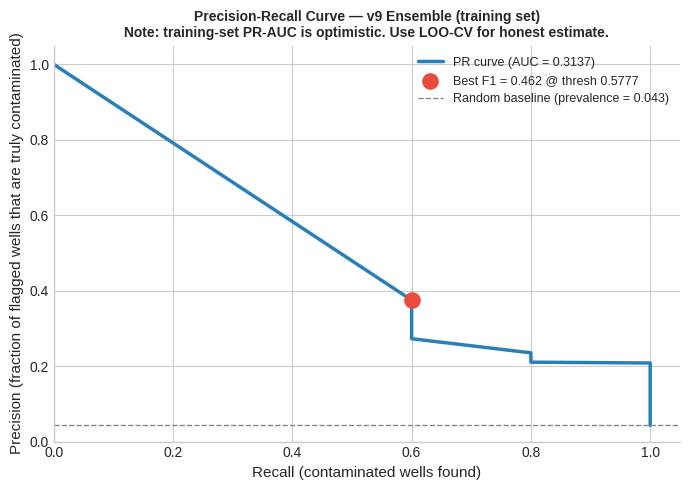


--- DETERMINISTIC PLUME MODEL ---
  Train:116 | Pred:73 | Military:6 | Industrial:1929
  Building source table...
  Total sources: 496
  Computing radial plume field...
  Calculating risk zones with soil vulnerability...
  Saved Final_Nebraska_PFAS_Risk_Zones.csv
  Critical: 73 | High: 0
  Building soil type grid...
  Computing plume score surface from 496 sources...
  Loading county boundaries...
  Scoring unmonitored wells from plume model...
  Rendering map...

Saved: Nebraska_PFAS_Template_Map.png
Saved: Nebraska_Well_Priority_Template.csv

PIPELINE COMPLETE
  Plume Model: Score = S × exp(−k × d) × V × OM_f × R_f × D_f
  ML Ensemble: ElasticNet LR + Calibrated RF (v9, DEBIASED)
  Sources: 496 | Wells scored: 73
  >500 ng/L: 2 | 100-500: 4 | 50-100: 3 | 10-50: 9 | 0-10: 55


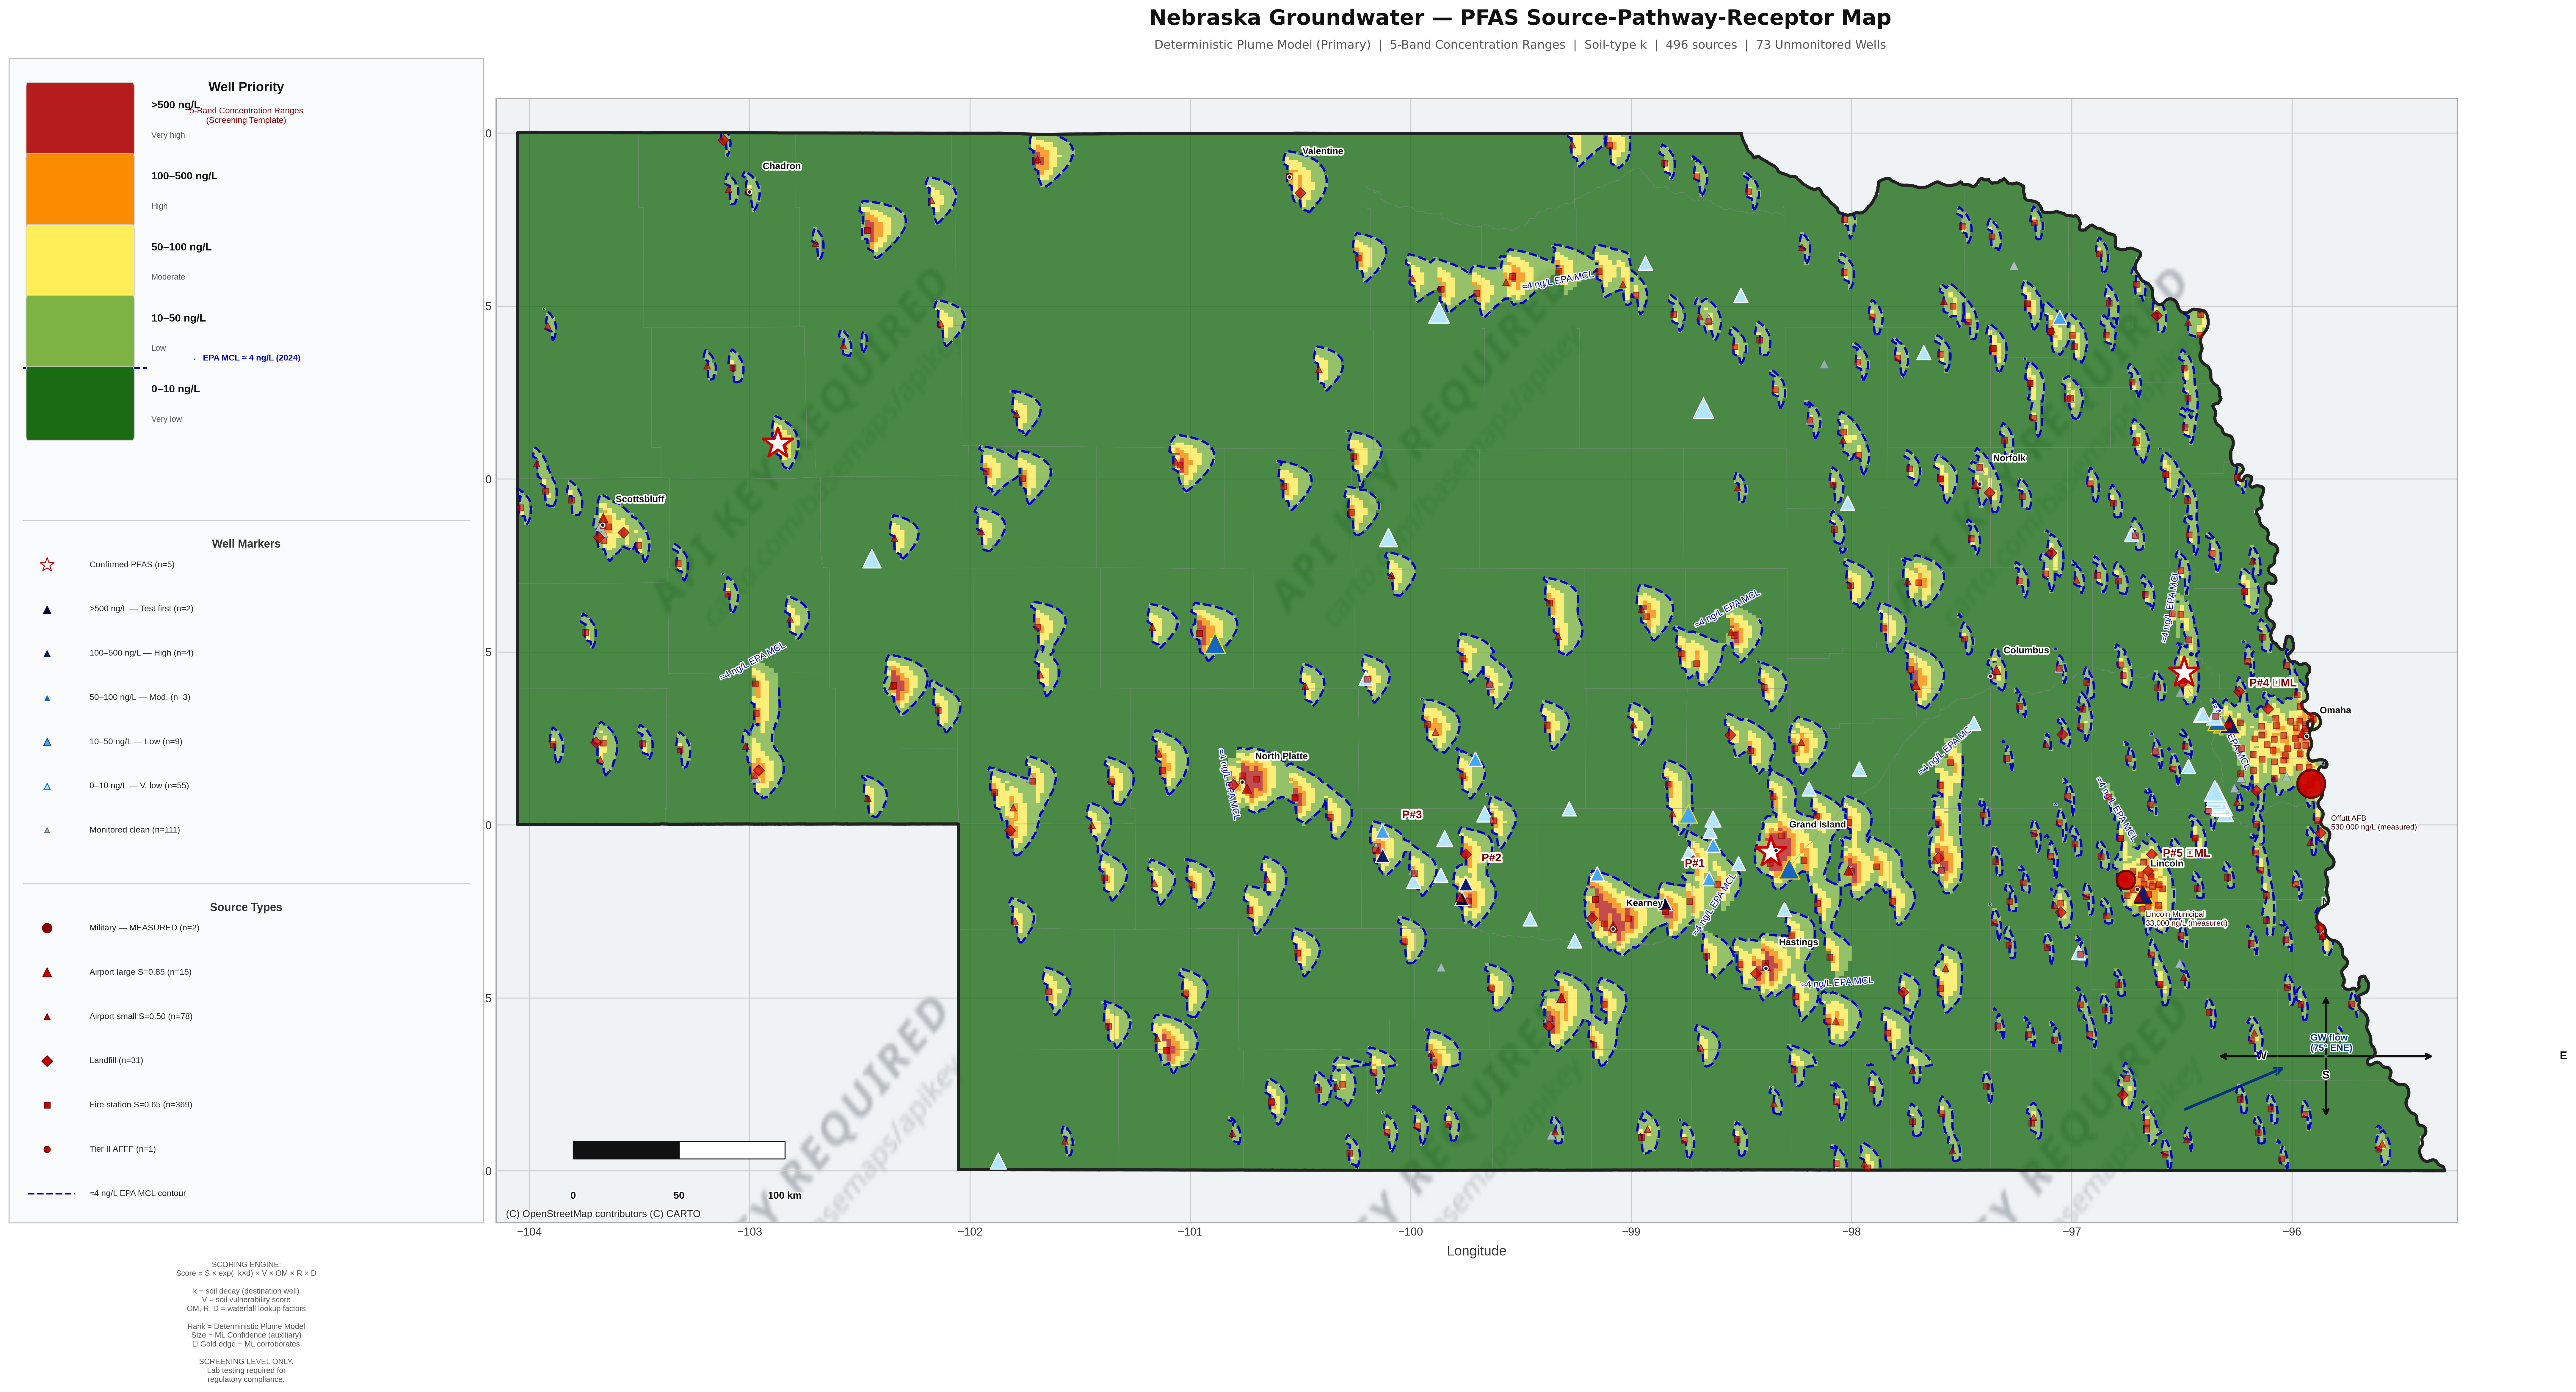

In [8]:
# -*- coding: utf-8 -*-
# =============================================================================
# PFAS GROUNDWATER CONTAMINATION PREDICTION — NEBRASKA
# Production Pipeline: Data Ingestion → Feature Engineering → ML Ensemble →
#                      Deterministic Plume Model → Deliverables
# =============================================================================

!pip install geopandas pykrige contextily openpyxl rasterio fiona pyproj shapely scikit-learn scipy seaborn -q

import os
import pickle

# --- CACHING CONFIGURATION ---------------------------------------------------
FORCE_RECOMPUTE = False
CACHE_DIR = '/content/pfas_cache/'
os.makedirs(CACHE_DIR, exist_ok=True)

if not os.path.exists('/content/pfas_data') or FORCE_RECOMPUTE:
    os.system('git clone https://huggingface.co/datasets/muhammadzaid270/pfas_data')

# --- IMPORTS ------------------------------------------------------------------

import pandas as pd
import geopandas as gpd
import numpy as np
import seaborn as sns
from pathlib import Path
from matplotlib import pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.metrics import precision_recall_curve, auc, f1_score, make_scorer
import warnings
warnings.filterwarnings('ignore')

# --- GLOBAL CONSTANTS --------------------------------------------------------

REPO_PATH = "/content/pfas_data"
RAW_DATA = f"{REPO_PATH}/raw_data"

TOLERANCE_METERS = 55000

data_files = [file for pattern in ("*.csv", "*.xlsx") for file in Path(RAW_DATA).rglob(pattern)]
file_dict  = {file.stem: file for file in data_files}

def load_data(name):
    if name not in file_dict:
        raise KeyError(f"File '{name}' not found in {RAW_DATA}")
    file_path = file_dict[name]
    if file_path.suffix == ".csv":
        return pd.read_csv(file_path, dtype=str)
    elif file_path.suffix in (".xlsx", ".xls"):
        return pd.read_excel(file_path, dtype=str, engine="openpyxl")
    else:
        raise ValueError("Unsupported file type")


# =============================================================================
# DATA INGESTION — USGS GROUNDWATER WELLS
# =============================================================================

def transform_groundwater():
    df = load_data("groundwater")

    df = df[df['site_tp_cd'] == 'GW'].copy()
    df['state_cd'] = df['state_cd'].str.strip()
    df = df[df['state_cd'] == '31']

    df = df.drop(columns=['agency_cd', 'country_cd', 'site_tp_cd', 'instruments_cd'], errors='ignore')
    df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

    for col in ['dec_lat_va', 'dec_long_va', 'well_depth_va', 'hole_depth_va', 'alt_va', 'alt_acy_va']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.dropna(subset=['dec_lat_va', 'dec_long_va'])

    for col in ['construction_dt', 'inventory_dt']:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors='coerce', format='mixed')

    return gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(df['dec_long_va'], df['dec_lat_va']),
        crs="EPSG:4326"
    )

wells_data = transform_groundwater()
wells_data.to_file("wells_data.gpkg", driver="GPKG")
print(f"USGS Wells: {len(wells_data)} wells | {wells_data['well_depth_va'].notna().sum()} with depth")

# =============================================================================
# DATA INGESTION — UCMR DRINKING WATER FACILITIES
# =============================================================================

def transform_ucmr():
    df = load_data("ucmr_drinking_water")

    df = df.apply(lambda x: x.str.replace('\xa0', ' ').str.strip() if x.dtype == "object" else x)
    df = df[df['State Territory or Tribe'].str.contains('NE', na=False)]
    df = df[df['Facility Water Type'].str.contains('GW-Groundwater', case=False, na=False)]
    df = df.drop(columns=['Tribal Name', 'PFAS Treatment'], errors='ignore')

    df['pfas_detect'] = df['Result At or Above UCMR MRL'].str.contains('Yes', case=False, na=False).astype(int)

    for col in ['Analytical Result Value (ng/L)', 'Minimum Reporting Level (ng/L)',
                'Latitude', 'Longitude', 'Population Served']:
        if col in df.columns:
            df[col] = df[col].replace('-', pd.NA)
            df[col] = pd.to_numeric(df[col], errors='coerce')

    if 'Collection Date' in df.columns:
        df['Collection Date'] = pd.to_datetime(df['Collection Date'], errors='coerce')

    df = df.dropna(subset=['Latitude', 'Longitude'])

    agg_df = df.groupby('Facility ID').agg(
        pfas_detect          = ('pfas_detect',                    'max'),
        max_concentration    = ('Analytical Result Value (ng/L)', 'max'),
        num_chemicals_tested = ('Contaminant',                    'nunique'),
        Latitude             = ('Latitude',                       'first'),
        Longitude            = ('Longitude',                      'first'),
        Facility_Name        = ('Facility Name',                  'first'),
        PWS_ID               = ('PWS ID',                         'first'),
        Population_Served    = ('Population Served',              'first'),
    ).reset_index()

    return gpd.GeoDataFrame(
        agg_df,
        geometry=gpd.points_from_xy(agg_df['Longitude'], agg_df['Latitude']),
        crs="EPSG:4326"
    )

ucmr_data = transform_ucmr()
ucmr_data.to_file("PFAS_Targets_Cleaned.gpkg", driver="GPKG")
print(f"UCMR: {len(ucmr_data)} facilities | Contaminated: {ucmr_data['pfas_detect'].sum()} | Clean: {(ucmr_data['pfas_detect']==0).sum()}")

# =============================================================================
# DATA INGESTION — FEDERAL / MILITARY SITES
# =============================================================================

def transform_federal_sites():
    df = load_data("federal_sites")
    df = df.apply(lambda x: x.str.replace('\xa0', ' ').str.strip() if x.dtype == "object" else x)
    df = df[df['State Territory or Tribe'].str.contains('NE', na=False)]

    df = df.rename(columns={
        'PFOA Maximum Detected in Groundwater (ppt)': 'PFOA_Max_ppt',
        'PFOS Maximum Detected in Groundwater (ppt)': 'PFOS_Max_ppt',
        'PFBS Maximum Detected in Groundwater (ppt)': 'PFBS_Max_ppt',
    })

    for col in ['PFOA_Max_ppt', 'PFOS_Max_ppt', 'PFBS_Max_ppt', 'Latitude', 'Longitude']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.replace(',', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce')

    df = df.drop(columns=['Link', 'State (Other)', 'Estimated PA/SI End Date',
                           'Estimated RI/FS End Date'], errors='ignore')
    df = df.dropna(subset=['Latitude', 'Longitude'])

    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['Longitude'], df['Latitude']), crs="EPSG:4326")

military_data = transform_federal_sites()
military_data.to_file("Federal_Sites_Cleaned.gpkg", driver="GPKG")
print(f"Military sites: {len(military_data)}")

# =============================================================================
# DATA INGESTION — EPA ECHO INDUSTRIAL SECTORS
# =============================================================================

def transform_i_sectors():
    df = load_data("industry_sectors")
    df = df.apply(lambda x: x.str.replace('\xa0', ' ').str.strip() if x.dtype == "object" else x)
    df = df[df['State'].str.contains('NE', na=False)]
    df = df.drop(columns=['ECHO Facility Report', 'Region', 'State (Other)'], errors='ignore')

    for col in ['Latitude', 'Longitude', 'FAC_POP_DEN', 'FAC_PERCENT_MINORITY',
                'FAC_INSPECTION_COUNT', 'FAC_INFORMAL_COUNT', 'FAC_FORMAL_ACTION_COUNT',
                'FAC_TOTAL_PENALTIES', 'FAC_PENALTY_COUNT', 'FAC_DAYS_LAST_INSPECTION',
                'FAC_LAST_PENALTY_AMT', 'FAC_QTRS_WITH_NC',
                'TRI_RELEASES_TRANSFERS', 'TRI_ON_SITE_RELEASES', 'TRI_OFF_SITE_TRANSFERS']:
        if col in df.columns:
            df[col] = df[col].replace('-', pd.NA)
            df[col] = df[col].astype(str).str.replace(',', '', regex=True)
            df[col] = pd.to_numeric(df[col], errors='coerce')

    for col in ['FAC_DATE_LAST_INSPECTION', 'FAC_DATE_LAST_INFORMAL_ACTION',
                'FAC_DATE_LAST_FORMAL_ACTION', 'FAC_DATE_LAST_PENALTY']:
        if col in df.columns:
            df[col] = df[col].replace('-', pd.NA)
            df[col] = pd.to_datetime(df[col], errors='coerce')

    df = df.dropna(subset=['Latitude', 'Longitude'])
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['Longitude'], df['Latitude']), crs="EPSG:4326")

industry_data = transform_i_sectors()
industry_data.to_file("Industry_Sectors_Cleaned.gpkg", driver="GPKG")
print(f"Industrial facilities: {len(industry_data)}")

# =============================================================================
# FEATURE ENGINEERING — AQUIFER VULNERABILITY ENCODING
# =============================================================================

def encode_aquifer_features(df):
    df['is_unconfined']  = df['aqfr_type_cd'].map({'U': 1, 'C': 0})
    df['nat_aqfr_risk']  = df['nat_aqfr_cd'].map({
        'N100ALLUVL': 2,
        'N100HGHPLN': 2,
        'N300LCRTCS': 0,
    })
    df['local_aqfr_risk'] = df['aqfr_cd'].map({
        '110SAGR':  2,
        '112SDGVD': 2,
        '112SDHL':  2,
        '110QRNR':  2,
        '111ALVM':  2,
        '110WDBS':  2,
        '121OGLL':  1,
        '211DKOT':  0,
    })
    return df

# =============================================================================
# FEATURE ENGINEERING — RISK & PROXIMITY
# =============================================================================

def engineer_risk_features(df):
    df['risk_index'] = df['dist_to_military_meters'] / df['well_depth_va'].replace(0, pd.NA)

    pfos = df['PFOS_Max_ppt'].fillna(0)
    pfoa = df['PFOA_Max_ppt'].fillna(0)

    df['idw_threat']          = pfos / (df['dist_to_military_meters'] + 1) ** 2
    df['idw_threat_combined'] = (pfos + pfoa) / (df['dist_to_military_meters'] + 1) ** 2

    return df

# =============================================================================
# FEATURE ENGINEERING — INDUSTRY DENSITY (O(n×m) spatial loop)
# =============================================================================

def engineer_density_features(df, industry):
    airports = industry[industry['Industry'].str.contains('Airport', case=False, na=False)].copy()

    df['industry_count_10km'] = 0
    df['industry_count_50km'] = 0
    df['airport_count_10km']  = 0

    for idx, row in df.iterrows():
        point          = row.geometry
        industry_dists = industry.geometry.distance(point)
        airport_dists  = airports.geometry.distance(point)
        df.at[idx, 'industry_count_10km'] = (industry_dists <= 10000).sum()
        df.at[idx, 'industry_count_50km'] = (industry_dists <= 50000).sum()
        df.at[idx, 'airport_count_10km']  = (airport_dists  <= 10000).sum()

    return df

def engineer_interaction_features(df):
    military_hazard = 50000 / (df['dist_to_military_meters'] + 1)
    df['hazard_density'] = military_hazard + df['airport_count_10km'] + df['industry_count_10km']
    df['source_depth_risk'] = df['hazard_density'] / (df['well_depth_va'].fillna(0) + 1)
    return df

# =============================================================================
# TRAINING PIPELINE — BUILD ML TRAINING MATRIX
# =============================================================================

def build_training_matrix():
    targets  = gpd.read_file("PFAS_Targets_Cleaned.gpkg")
    wells    = gpd.read_file("wells_data.gpkg")
    military = gpd.read_file("Federal_Sites_Cleaned.gpkg")
    industry = gpd.read_file("Industry_Sectors_Cleaned.gpkg")

    print("  Reprojecting to EPSG:32614...")
    targets  = targets.to_crs(epsg=32614)
    wells    = wells.to_crs(epsg=32614)
    military = military.to_crs(epsg=32614)
    industry = industry.to_crs(epsg=32614)

    print("  Joining USGS well attributes...")
    targets = gpd.sjoin_nearest(
        targets,
        wells[['well_depth_va', 'aqfr_type_cd', 'nat_aqfr_cd', 'aqfr_cd', 'geometry']],
        how='left',
        distance_col='dist_to_usgs_match'
    )
    targets = targets[~targets.index.duplicated(keep='first')]
    targets = targets.drop(columns=['index_right'], errors='ignore')

    too_far = targets['dist_to_usgs_match'] > TOLERANCE_METERS
    for col in ['well_depth_va', 'aqfr_type_cd', 'nat_aqfr_cd', 'aqfr_cd']:
        targets.loc[too_far, col] = pd.NA

    print("  Joining military site data...")
    targets = gpd.sjoin_nearest(
        targets,
        military[['PFOS_Max_ppt', 'PFOA_Max_ppt', 'geometry']],
        how='left',
        distance_col='dist_to_military_meters'
    )
    targets = targets[~targets.index.duplicated(keep='first')]
    targets = targets.drop(columns=['index_right'], errors='ignore')

    print("  Joining industry data...")
    targets = gpd.sjoin_nearest(
        targets,
        industry[['Industry', 'geometry']],
        how='left',
        distance_col='dist_to_industry_meters'
    )
    targets = targets[~targets.index.duplicated(keep='first')]
    targets = targets.drop(columns=['index_right'], errors='ignore')

    print("  Engineering features...")
    targets = encode_aquifer_features(targets)
    targets = engineer_risk_features(targets)
    targets = engineer_density_features(targets, industry)
    targets = engineer_interaction_features(targets)

    return targets

print("\n--- BUILDING TRAINING MATRIX ---")
_CACHE_TRAIN_BASE = f"{CACHE_DIR}/01_training_matrix_base.parquet"
if os.path.exists(_CACHE_TRAIN_BASE) and not FORCE_RECOMPUTE:
    print("Loading cached training matrix...")
    training_matrix = gpd.read_parquet(_CACHE_TRAIN_BASE)
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")
else:
    training_matrix = build_training_matrix()
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")
    training_matrix.to_parquet(_CACHE_TRAIN_BASE)
print(f"Training matrix: {len(training_matrix)} rows | {training_matrix['pfas_detect'].sum()} contaminated | {(training_matrix['pfas_detect']==0).sum()} clean")

# =============================================================================
# PREDICTION PIPELINE — BUILD WELL PREDICTION MATRIX
# =============================================================================

def build_prediction_matrix():
    wells    = gpd.read_file("wells_data.gpkg")
    military = gpd.read_file("Federal_Sites_Cleaned.gpkg")
    industry = gpd.read_file("Industry_Sectors_Cleaned.gpkg")

    print("  Reprojecting to EPSG:32614...")
    wells    = wells.to_crs(epsg=32614)
    military = military.to_crs(epsg=32614)
    industry = industry.to_crs(epsg=32614)

    print("  Joining military site data...")
    wells = gpd.sjoin_nearest(
        wells,
        military[['PFOS_Max_ppt', 'PFOA_Max_ppt', 'geometry']],
        how='left',
        distance_col='dist_to_military_meters'
    )
    wells = wells[~wells.index.duplicated(keep='first')]
    wells = wells.drop(columns=['index_right'], errors='ignore')

    print("  Joining industry data...")
    wells = gpd.sjoin_nearest(
        wells,
        industry[['Industry', 'geometry']],
        how='left',
        distance_col='dist_to_industry_meters'
    )
    wells = wells[~wells.index.duplicated(keep='first')]
    wells = wells.drop(columns=['index_right'], errors='ignore')

    print("  Engineering features...")
    wells = encode_aquifer_features(wells)
    wells = engineer_risk_features(wells)
    wells = engineer_density_features(wells, industry)
    wells = engineer_interaction_features(wells)

    return wells

print("\n--- BUILDING PREDICTION MATRIX ---")
_CACHE_PRED_BASE = f"{CACHE_DIR}/01_prediction_matrix_base.parquet"
if os.path.exists(_CACHE_PRED_BASE) and not FORCE_RECOMPUTE:
    print("Loading cached prediction matrix...")
    prediction_matrix = gpd.read_parquet(_CACHE_PRED_BASE)
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")
else:
    prediction_matrix = build_prediction_matrix()
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")
    prediction_matrix.to_parquet(_CACHE_PRED_BASE)
print(f"Prediction matrix: {len(prediction_matrix)} wells ready to score")


# =============================================================================
# CHECKPOINT: TIER II CHEMICAL ENRICHMENT
# =============================================================================
_CACHE_TRAIN_TIER2 = f"{CACHE_DIR}/02_training_tier2.parquet"
_CACHE_PRED_TIER2  = f"{CACHE_DIR}/02_prediction_tier2.parquet"
_skip_tier2 = (os.path.exists(_CACHE_TRAIN_TIER2) and
              os.path.exists(_CACHE_PRED_TIER2) and
              not FORCE_RECOMPUTE)
if _skip_tier2:
    print("Loading cached Tier II data...")
    training_matrix = gpd.read_parquet(_CACHE_TRAIN_TIER2)
    prediction_matrix = gpd.read_parquet(_CACHE_PRED_TIER2)
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_tier2:

    import pandas as pd
    import geopandas as gpd
    import numpy as np


    TIER2_CHEMICALS   = f"{REPO_PATH}/raw_data/chemicals.csv"
    TIER2_COORDINATES = f"{REPO_PATH}/raw_data/coordinates.csv"
    TIER2_FACILITIES  = f"{REPO_PATH}/raw_data/facilities.csv"
    TIER2_CONTACTS    = f"{REPO_PATH}/raw_data/contacts.csv"

    # --- AMOUNT CODE → POUNDS MIDPOINT (40 CFR Part 370) ----------------------

    AMOUNT_CODE_MAP = {
        '01': 50,
        '02': 500,
        '03': 5_000,
        '04': 25_000,
        '05': 75_000,
        '06': 250_000,
        '07': 750_000,
        '08': 1_500_000,
        '09': 3_500_000,
        '10': 75_000_000,
        '11': 150_000_000,
        '12': 350_000_000,
        '13': 750_000_000,
    }

    print("Loading Tier II files...")
    chem  = pd.read_csv(TIER2_CHEMICALS,   dtype=str, encoding='latin1')
    coord = pd.read_csv(TIER2_COORDINATES, dtype=str, encoding='latin1')
    fac   = pd.read_csv(TIER2_FACILITIES,  dtype=str, encoding='latin1')
    cont  = pd.read_csv(TIER2_CONTACTS,    dtype=str, encoding='latin1')

    for df in [chem, coord, fac, cont]:
        for col in df.columns:
            if df[col].dtype == object or str(df[col].dtype) in ('str', 'string'):
                df[col] = df[col].str.strip()

    hazard_cols = [c for c in chem.columns if c.startswith('Hazard_')]
    for col in hazard_cols:
        chem[col] = (chem[col] == 'T').astype(int)

    yn_flag_cols = ['CONF', 'DEL', 'FIRE', 'GAS', 'IMM', 'LIQUID',
                    'MIX', 'PURE', 'REAC', 'SOLID', 'SUDREL']
    for col in yn_flag_cols:
        if col in chem.columns:
            chem[col] = (chem[col] == 'Y').astype(int)

    if 'PRSSRE' in chem.columns:
        chem['PRSSRE'] = pd.to_numeric(chem['PRSSRE'], errors='coerce').fillna(0).astype(int)

    chem['STDAYS'] = pd.to_numeric(chem['STDAYS'], errors='coerce').fillna(0)

    if 'STORCD' in chem.columns:
        chem['is_underground_storage'] = (chem['STORCD'] == 'B').astype(int)

    # --- AMOUNT CODE MAPPING --------------------------------------------------

    chem['max_lbs'] = chem['max amount code'].str.strip().map(AMOUNT_CODE_MAP).fillna(0)
    chem['avg_lbs'] = chem['avg amount code'].str.strip().map(AMOUNT_CODE_MAP).fillna(0)

    chem['hazard_score']    = chem[hazard_cols].sum(axis=1)
    chem['pressure_factor'] = 1 + (chem['SUDREL'] * chem['PRSSRE'] * 0.25)
    chem['weighted_threat'] = (
        chem['max_lbs']
        * chem['hazard_score']
        * (chem['STDAYS'] / 365)
        * chem['pressure_factor']
    )

    # --- FLAG PFAS-RELEVANT CHEMICALS -----------------------------------------

    AFFF_KEYWORDS   = ['afff', 'aqueous film', 'perfluoro', 'fluorotelomer']
    FLUORO_KEYWORDS = ['fluoro', 'fluorosil', 'fluoroethane', 'fluoropropene',
                       'fluorosilicic', 'trifluoro', 'tetrafluoro', 'difluoro']

    rptnam_lower    = chem['RPTNAM'].str.lower().fillna('')
    chem['is_afff']   = rptnam_lower.str.contains('|'.join(AFFF_KEYWORDS),   regex=True).astype(int)
    chem['is_fluoro'] = rptnam_lower.str.contains('|'.join(FLUORO_KEYWORDS), regex=True).astype(int)

    afff_facids   = set(chem[chem['is_afff']   == 1]['FACID'])
    fluoro_facids = set(chem[chem['is_fluoro'] == 1]['FACID'])

    # --- FACILITY-LEVEL AGGREGATION -------------------------------------------

    fac_agg = chem.groupby('FACID').agg(
        tier2_total_weighted_threat = ('weighted_threat',         'sum'),
        tier2_max_weighted_threat   = ('weighted_threat',         'max'),
        tier2_num_chemicals         = ('RPTNAM',                  'nunique'),
        tier2_total_max_lbs         = ('max_lbs',                 'sum'),
        tier2_hazard_score_sum      = ('hazard_score',            'sum'),
        tier2_has_carcinogen        = ('Hazard_carcinogen',        'max'),
        tier2_has_acutetox          = ('Hazard_acuteToxicity',     'max'),
        tier2_has_reproductive      = ('Hazard_reprodToxicity',    'max'),
        tier2_has_explosive         = ('Hazard_explosive',         'max'),
        tier2_has_fire_hazard       = ('FIRE',                    'max'),
        tier2_has_sudden_release    = ('SUDREL',                  'max'),
        tier2_has_reactivity        = ('REAC',                    'max'),
        tier2_has_underground       = ('is_underground_storage',  'max'),
        tier2_max_pressure_level    = ('PRSSRE',                  'max'),
    ).reset_index()

    fac_agg['tier2_is_afff']   = fac_agg['FACID'].isin(afff_facids).astype(int)
    fac_agg['tier2_is_fluoro'] = fac_agg['FACID'].isin(fluoro_facids).astype(int)

    # --- ATTACH COUNTY FROM facilities.csv ------------------------------------

    fac_meta = fac[['Facility ID', 'County', 'Facility City', 'Facility ZIP']].copy()
    fac_meta = fac_meta.rename(columns={'Facility ID': 'FACID'})
    fac_agg  = fac_agg.merge(fac_meta, on='FACID', how='left')

    # --- ATTACH COORDINATES ---------------------------------------------------

    coord['LAT'] = pd.to_numeric(coord['LAT'], errors='coerce')
    coord['LON'] = pd.to_numeric(coord['LON'], errors='coerce')
    coord['LON'] = -coord['LON'].abs()
    coord['YR']  = pd.to_numeric(coord['YR'],  errors='coerce')

    coord_latest = (
        coord.sort_values('YR', ascending=False)
             .drop_duplicates('FACID')[['FACID', 'LAT', 'LON', 'LLSRC']]
    )

    fac_final = fac_agg.merge(coord_latest, on='FACID', how='left')

    fac_spatial = fac_final.dropna(subset=['LAT', 'LON'])

    # --- BUILD GEODATAFRAME ---------------------------------------------------

    tier2_gdf = gpd.GeoDataFrame(
        fac_spatial,
        geometry=gpd.points_from_xy(fac_spatial['LON'], fac_spatial['LAT']),
        crs="EPSG:4326"
    ).to_crs(epsg=32614)

    afff_gdf   = tier2_gdf[tier2_gdf['tier2_is_afff']            == 1].copy()
    fluoro_gdf = tier2_gdf[tier2_gdf['tier2_is_fluoro']           == 1].copy()
    carcin_gdf = tier2_gdf[tier2_gdf['tier2_has_carcinogen']      == 1].copy()
    sudrel_gdf = tier2_gdf[tier2_gdf['tier2_has_sudden_release']  == 1].copy()

    print(f"  Tier II GeoDataFrame: {len(tier2_gdf):,} facilities")

    # --- SPATIAL FEATURE ENGINEERING ------------------------------------------

    TIER2_FEATURE_COLS = [
        'tier2_afff_count_10km',
        'tier2_afff_count_25km',
        'tier2_fluoro_count_10km',
        'tier2_carcinogen_count_10km',
        'tier2_sudrel_count_10km',
        'tier2_weighted_threat_10km',
        'tier2_weighted_threat_25km',
        'tier2_max_threat_nearest',
        'tier2_dist_nearest_afff_m',
    ]

    def engineer_tier2_features(df, tier2, afff, fluoro, carcin, sudrel):
        for col in TIER2_FEATURE_COLS:
            df[col] = 0.0
        df['tier2_dist_nearest_afff_m'] = np.nan

        for idx, row in df.iterrows():
            pt = row.geometry

            all_dists    = tier2.geometry.distance(pt)
            afff_dists   = afff.geometry.distance(pt)   if len(afff)   > 0 else pd.Series(dtype=float)
            fluoro_dists = fluoro.geometry.distance(pt) if len(fluoro) > 0 else pd.Series(dtype=float)
            carcin_dists = carcin.geometry.distance(pt) if len(carcin) > 0 else pd.Series(dtype=float)
            sudrel_dists = sudrel.geometry.distance(pt) if len(sudrel) > 0 else pd.Series(dtype=float)

            mask_10km = all_dists <= 10_000
            mask_25km = all_dists <= 25_000

            df.at[idx, 'tier2_afff_count_10km']       = (afff_dists   <= 10_000).sum() if len(afff_dists)   > 0 else 0
            df.at[idx, 'tier2_afff_count_25km']       = (afff_dists   <= 25_000).sum() if len(afff_dists)   > 0 else 0
            df.at[idx, 'tier2_fluoro_count_10km']     = (fluoro_dists <= 10_000).sum() if len(fluoro_dists) > 0 else 0
            df.at[idx, 'tier2_carcinogen_count_10km'] = (carcin_dists <= 10_000).sum() if len(carcin_dists) > 0 else 0
            df.at[idx, 'tier2_sudrel_count_10km']     = (sudrel_dists <= 10_000).sum() if len(sudrel_dists) > 0 else 0

            df.at[idx, 'tier2_weighted_threat_10km']  = tier2.loc[mask_10km, 'tier2_total_weighted_threat'].sum()
            df.at[idx, 'tier2_weighted_threat_25km']  = tier2.loc[mask_25km, 'tier2_total_weighted_threat'].sum()

            nearest_idx = all_dists.idxmin()
            df.at[idx, 'tier2_max_threat_nearest']    = tier2.loc[nearest_idx, 'tier2_total_weighted_threat']

            if len(afff_dists) > 0:
                df.at[idx, 'tier2_dist_nearest_afff_m'] = afff_dists.min()

        return df

    print("  Enriching training matrix with Tier II features...")
    training_matrix = gpd.read_file("ML_Training_Matrix.gpkg").to_crs(epsg=32614)
    training_matrix = engineer_tier2_features(
        training_matrix, tier2_gdf, afff_gdf, fluoro_gdf, carcin_gdf, sudrel_gdf
    )
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")

    print("  Enriching prediction matrix with Tier II features...")
    prediction_matrix = gpd.read_file("Wells_Prediction_Matrix.gpkg").to_crs(epsg=32614)
    prediction_matrix = engineer_tier2_features(
        prediction_matrix, tier2_gdf, afff_gdf, fluoro_gdf, carcin_gdf, sudrel_gdf
    )
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

    training_matrix.to_parquet(_CACHE_TRAIN_TIER2)
    prediction_matrix.to_parquet(_CACHE_PRED_TIER2)
    print("  Tier II enrichment cached.")



# =============================================================================
# CHECKPOINT: USDA CROPLAND DATA LAYER (CDL)
# =============================================================================
_CACHE_TRAIN_CDL = f"{CACHE_DIR}/03_training_cdl.parquet"
_CACHE_PRED_CDL  = f"{CACHE_DIR}/03_prediction_cdl.parquet"
_skip_cdl = (os.path.exists(_CACHE_TRAIN_CDL) and
              os.path.exists(_CACHE_PRED_CDL) and
              not FORCE_RECOMPUTE)
if _skip_cdl:
    print("Loading cached CDL data...")
    training_matrix = gpd.read_parquet(_CACHE_TRAIN_CDL)
    prediction_matrix = gpd.read_parquet(_CACHE_PRED_CDL)
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_cdl:

    import os
    import subprocess
    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import rasterio
    import rasterio.mask
    from rasterio.warp import transform_bounds
    from shapely.geometry import mapping
    import warnings
    warnings.filterwarnings('ignore')

    import zipfile

    ZIP_PATH    = f"{REPO_PATH}/raw_data/cropland.zip"
    EXTRACT_DIR = "/content/cdl_extracted"
    TIF_PATH    = f"{EXTRACT_DIR}/cropland.tif"

    os.makedirs(EXTRACT_DIR, exist_ok=True)

    if not os.path.exists(TIF_PATH):
        print("Extracting cropland.zip...")

        with zipfile.ZipFile(ZIP_PATH, 'r') as z:
            z.extractall(EXTRACT_DIR)

        for root, dirs, files in os.walk(EXTRACT_DIR):
            for f in files:
                if f.endswith('.tif') or f.endswith('.img'):
                    TIF_PATH = os.path.join(root, f)
                    break

    CDL_CODES = {
        1:   'Corn',
        2:   'Cotton',
        5:   'Soybeans',
        6:   'Sunflower',
        21:  'Barley',
        22:  'Durum Wheat',
        23:  'Spring Wheat',
        24:  'Winter Wheat',
        27:  'Rye',
        28:  'Oats',
        29:  'Millet',
        31:  'Canola',
        32:  'Flaxseed',
        33:  'Safflower',
        36:  'Alfalfa',
        37:  'Other Hay/Non Alfalfa',
        42:  'Dry Beans',
        51:  'Sorghum',
        52:  'Lentils',
        53:  'Peas',
        54:  'Tomatoes',
        61:  'Fallow/Idle Cropland',
        111: 'Open Water',
        121: 'Developed/Open Space',
        122: 'Developed/Low Intensity',
        123: 'Developed/Med Intensity',
        124: 'Developed/High Intensity',
        131: 'Barren',
        141: 'Deciduous Forest',
        142: 'Evergreen Forest',
        143: 'Mixed Forest',
        152: 'Shrubland',
        176: 'Grassland/Pasture',
        190: 'Woody Wetlands',
        195: 'Herbaceous Wetlands',
    }

    IRRIGATED_CROP_CODES  = {1, 5, 6, 51, 54}
    BIOSOLID_RISK_CODES   = {36, 37, 61}
    ALL_CROP_CODES        = set(range(1, 100))
    DEVELOPED_CODES       = {121, 122, 123, 124}

    with rasterio.open(TIF_PATH) as src:
        meta = src.meta
        bounds = src.bounds
        crs = src.crs
        res = src.res
        shape = src.shape

        data_sample = src.read(1)[::50, ::50]
        unique_codes = np.unique(data_sample[data_sample != meta['nodata']])

    print("  Loading matrices for CDL sampling...")
    training_matrix   = gpd.read_file("ML_Training_Matrix.gpkg")
    prediction_matrix = gpd.read_file("Wells_Prediction_Matrix.gpkg")

    def sample_cdl_features(gdf, tif_path, cdl_codes_map,
                             irrigated, biosolid_risk, all_crops, developed,
                             radii_m=(1000, 5000)):
        """Sample CDL raster at well locations and compute land-use percentages."""
        with rasterio.open(tif_path) as src:
            raster_crs = src.crs
            nodata     = src.meta['nodata'] or 0

            gdf_raster = gdf.to_crs(raster_crs)

            results = []

            for idx, row in gdf_raster.iterrows():
                pt  = row.geometry
                rec = {'index': idx}

                try:
                    pt_val = list(src.sample([(pt.x, pt.y)]))[0][0]
                    rec['cdl_point_code']       = int(pt_val) if pt_val != nodata else -1
                    rec['cdl_is_cropland_point'] = 1 if int(pt_val) in all_crops else 0
                except Exception:
                    rec['cdl_point_code']        = -1
                    rec['cdl_is_cropland_point'] = 0

                for r in radii_m:
                    label = f"{r//1000}km"
                    try:
                        buffer   = pt.buffer(r)
                        window   = rasterio.mask.geometry_window(src, [mapping(buffer)])
                        masked, _ = rasterio.mask.mask(
                            src, [mapping(buffer)],
                            crop=True, nodata=nodata, filled=True
                        )
                        pixels = masked[0].flatten()
                        valid  = pixels[pixels != nodata]

                        if len(valid) == 0:
                            rec[f'cdl_crop_pct_{label}']      = np.nan
                            rec[f'cdl_irrigated_pct_{label}'] = np.nan
                            rec[f'cdl_biosolid_pct_{label}']  = np.nan
                            rec[f'cdl_developed_pct_{label}'] = np.nan
                            continue

                        total = len(valid)
                        rec[f'cdl_crop_pct_{label}']      = np.isin(valid, list(all_crops)).sum()      / total
                        rec[f'cdl_irrigated_pct_{label}'] = np.isin(valid, list(irrigated)).sum()      / total
                        rec[f'cdl_biosolid_pct_{label}']  = np.isin(valid, list(biosolid_risk)).sum()  / total
                        rec[f'cdl_developed_pct_{label}'] = np.isin(valid, list(developed)).sum()      / total

                    except Exception as e:
                        rec[f'cdl_crop_pct_{label}']      = np.nan
                        rec[f'cdl_irrigated_pct_{label}'] = np.nan
                        rec[f'cdl_biosolid_pct_{label}']  = np.nan
                        rec[f'cdl_developed_pct_{label}'] = np.nan

                results.append(rec)

        return pd.DataFrame(results).set_index('index')

    print("  Sampling CDL — training matrix...")
    train_cdl = sample_cdl_features(
        training_matrix, TIF_PATH,
        CDL_CODES, IRRIGATED_CROP_CODES, BIOSOLID_RISK_CODES,
        ALL_CROP_CODES, DEVELOPED_CODES
    )

    print("  Sampling CDL — prediction matrix...")
    pred_cdl = sample_cdl_features(
        prediction_matrix, TIF_PATH,
        CDL_CODES, IRRIGATED_CROP_CODES, BIOSOLID_RISK_CODES,
        ALL_CROP_CODES, DEVELOPED_CODES
    )

    # --- CDL FEATURE SELECTION (contaminated vs clean comparison) --------------

    train_cdl['pfas_detect'] = training_matrix['pfas_detect'].astype(int).values

    cdl_feature_cols = [c for c in train_cdl.columns if c.startswith('cdl_') and c != 'pfas_detect']

    contaminated = train_cdl[train_cdl['pfas_detect'] == 1]
    clean        = train_cdl[train_cdl['pfas_detect'] == 0]

    useful_features = []
    for col in cdl_feature_cols:
        c_mean = contaminated[col].mean()
        cl_mean = clean[col].mean()
        if pd.isna(c_mean) or pd.isna(cl_mean):
            continue
        diff = c_mean - cl_mean
        useful = abs(diff) > 0.05 or (cl_mean > 0 and abs(diff / cl_mean) > 0.20)
        if useful:
            useful_features.append(col)

    CDL_FEATURE_COLS = useful_features if useful_features else cdl_feature_cols

    training_matrix = training_matrix.join(train_cdl[CDL_FEATURE_COLS], how='left')
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")

    prediction_matrix = prediction_matrix.join(pred_cdl[CDL_FEATURE_COLS], how='left')
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

    training_matrix.to_parquet(_CACHE_TRAIN_CDL)
    prediction_matrix.to_parquet(_CACHE_PRED_CDL)
    print("  CDL enrichment cached.")



# =============================================================================
# CHECKPOINT: LMOP LANDFILL ENRICHMENT
# =============================================================================
_CACHE_TRAIN_LMOP = f"{CACHE_DIR}/04_training_lmop.parquet"
_CACHE_PRED_LMOP  = f"{CACHE_DIR}/04_prediction_lmop.parquet"
_skip_lmop = (os.path.exists(_CACHE_TRAIN_LMOP) and
              os.path.exists(_CACHE_PRED_LMOP) and
              not FORCE_RECOMPUTE)
if _skip_lmop:
    print("Loading cached LMOP data...")
    training_matrix = gpd.read_parquet(_CACHE_TRAIN_LMOP)
    prediction_matrix = gpd.read_parquet(_CACHE_PRED_LMOP)
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_lmop:

    import pandas as pd
    import geopandas as gpd
    import numpy as np
    import warnings
    warnings.filterwarnings('ignore')

    LMOP_PATH = f"{REPO_PATH}/raw_data/landfills.xlsx"

    xl = pd.ExcelFile(LMOP_PATH)

    df = pd.read_excel(LMOP_PATH, sheet_name='LMOP Database', header=0)

    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.strip().replace('nan', np.nan)

    numeric_cols = [
        'Latitude', 'Longitude',
        'Year Landfill Opened', 'Landfill Closure Year',
        'Waste in Place (tons)',
        'LFG Collected (mmscfd)',
        'LFG Flared (mmscfd)',
        'LFG Flow to Project (mmscfd)',
        'Actual MW Generation',
        'Rated MW Capacity',
    ]
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    df['lfg_collection'] = df['LFG Collection System In Place?'].map(
        {'Yes': 1, 'No': 0, 'Unknown': np.nan}
    )

    df['is_open'] = (df['Current Landfill Status'].str.strip() == 'Open').astype(int)

    df['year_opened']  = df['Year Landfill Opened']
    df['year_closed']  = df['Landfill Closure Year']
    df['years_active'] = df.apply(
        lambda r: (r['year_closed'] if pd.notna(r['year_closed']) else 2024) - r['year_opened']
        if pd.notna(r['year_opened']) else np.nan,
        axis=1
    )

    def leachate_risk(row):
        if row['lfg_collection'] == 1:
            return 0
        wip = row['Waste in Place (tons)']
        if row['is_open'] == 1:
            return 2
        elif pd.notna(wip) and wip > 1_000_000:
            return 1
        else:
            return 1

    df['leachate_risk_score'] = df.apply(leachate_risk, axis=1)

    landfills = df.groupby('Landfill ID').agg(
        Landfill_Name        = ('Landfill Name',          'first'),
        Latitude             = ('Latitude',                'first'),
        Longitude            = ('Longitude',               'first'),
        is_open              = ('is_open',                 'first'),
        waste_in_place_tons  = ('Waste in Place (tons)',   'first'),
        lfg_collection       = ('lfg_collection',          'first'),
        year_opened          = ('year_opened',             'first'),
        years_active         = ('years_active',            'first'),
        leachate_risk_score  = ('leachate_risk_score',     'max'),
        County               = ('County',                  'first'),
        City                 = ('City',                    'first'),
    ).reset_index()

    print(f"  Deduplicated: {len(df)} rows → {len(landfills)} unique landfills")

    landfills_spatial = landfills.dropna(subset=['Latitude','Longitude']).copy()

    lmop_gdf = gpd.GeoDataFrame(
        landfills_spatial,
        geometry=gpd.points_from_xy(landfills_spatial['Longitude'], landfills_spatial['Latitude']),
        crs="EPSG:4326"
    ).to_crs(epsg=32614)

    LMOP_FEATURE_COLS = [
        'lmop_count_10km',
        'lmop_count_25km',
        'lmop_waste_volume_10km',
        'lmop_waste_volume_25km',
        'lmop_uncontrolled_10km',
        'lmop_dist_nearest_m',
        'lmop_leachate_risk_10km',
    ]

    high_risk_gdf = lmop_gdf[lmop_gdf['leachate_risk_score'] == 2].copy()

    def engineer_lmop_features(df, lmop, high_risk):
        for col in LMOP_FEATURE_COLS:
            df[col] = 0.0
        df['lmop_dist_nearest_m'] = np.nan

        for idx, row in df.iterrows():
            pt       = row.geometry
            all_dist = lmop.geometry.distance(pt)

            mask_10km = all_dist <= 10_000
            mask_25km = all_dist <= 25_000

            df.at[idx, 'lmop_count_10km']  = mask_10km.sum()
            df.at[idx, 'lmop_count_25km']  = mask_25km.sum()

            wip = lmop['waste_in_place_tons'].fillna(0)
            df.at[idx, 'lmop_waste_volume_10km'] = wip[mask_10km].sum()
            df.at[idx, 'lmop_waste_volume_25km'] = wip[mask_25km].sum()

            uncontrolled = lmop['lfg_collection'].fillna(0) == 0
            df.at[idx, 'lmop_uncontrolled_10km'] = (mask_10km & uncontrolled).sum()

            df.at[idx, 'lmop_leachate_risk_10km'] = lmop.loc[mask_10km, 'leachate_risk_score'].sum()

            if len(all_dist) > 0:
                df.at[idx, 'lmop_dist_nearest_m'] = all_dist.min()

        return df

    print("  Enriching training matrix with LMOP features...")
    training_matrix = gpd.read_file("ML_Training_Matrix.gpkg").to_crs(epsg=32614)
    training_matrix = engineer_lmop_features(training_matrix, lmop_gdf, high_risk_gdf)
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")

    print("  Enriching prediction matrix with LMOP features...")
    prediction_matrix = gpd.read_file("Wells_Prediction_Matrix.gpkg").to_crs(epsg=32614)
    prediction_matrix = engineer_lmop_features(prediction_matrix, lmop_gdf, high_risk_gdf)
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

    training_matrix.to_parquet(_CACHE_TRAIN_LMOP)
    prediction_matrix.to_parquet(_CACHE_PRED_LMOP)
    print("  LMOP enrichment cached.")



# =============================================================================
# CHECKPOINT: gSSURGO SOIL ENRICHMENT
# =============================================================================
_CACHE_TRAIN_GSSURGO = f"{CACHE_DIR}/05_training_gssurgo.parquet"
_CACHE_PRED_GSSURGO  = f"{CACHE_DIR}/05_prediction_gssurgo.parquet"
_CACHE_SOIL_ATTRS    = f"{CACHE_DIR}/05_soil_attrs.pkl"
_CACHE_MUPOLYGON     = f"{CACHE_DIR}/05_mupolygon.parquet"
_skip_gssurgo = (os.path.exists(_CACHE_TRAIN_GSSURGO) and
                 os.path.exists(_CACHE_PRED_GSSURGO) and
                 not FORCE_RECOMPUTE)
if _skip_gssurgo:
    print("Loading cached gSSURGO data...")
    training_matrix = gpd.read_parquet(_CACHE_TRAIN_GSSURGO)
    prediction_matrix = gpd.read_parquet(_CACHE_PRED_GSSURGO)
    training_matrix.to_file("ML_Training_Matrix.gpkg", driver="GPKG")
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_gssurgo:
    # --- Sub-cache: soil attribute table --------------------------------------
    _skip_soil_attrs = (os.path.exists(_CACHE_SOIL_ATTRS) and not FORCE_RECOMPUTE)
    if _skip_soil_attrs:
        print("Loading cached soil attributes...")
        with open(_CACHE_SOIL_ATTRS, 'rb') as _f:
            soil_attrs = pickle.load(_f)

    if not _skip_soil_attrs:

        import os
        import zipfile
        import warnings
        import numpy as np
        import pandas as pd
        import geopandas as gpd
        import fiona
        warnings.filterwarnings('ignore')

        GSSURGO_ZIP = f"{REPO_PATH}/raw_data/gSSURGO_NE.zip"
        EXTRACT_DIR = "/content/gssurgo_extracted"
        GDB_PATH    = f"{EXTRACT_DIR}/gSSURGO_NE.gdb"

        if not os.path.exists(GDB_PATH):
            print("  Extracting gSSURGO_NE.zip...")
            with zipfile.ZipFile(GSSURGO_ZIP, 'r') as z:
                z.extractall(EXTRACT_DIR)
        else:
            print(f"  gSSURGO already extracted.")

        print("  Loading gSSURGO table layers...")

        dom_comp  = gpd.read_file(GDB_PATH, layer='DominantComponent')
        dom_comp  = dom_comp[['mukey', 'cokey', 'comppct_r']].copy()

        component = gpd.read_file(GDB_PATH, layer='component')
        comp_cols = [c for c in ['cokey','hydgrp','slope_r','drainagecl','wei','weg']
                     if c in component.columns]
        component = component[comp_cols].copy()

        chorizon  = gpd.read_file(GDB_PATH, layer='chorizon')
        hor_cols  = [c for c in ['cokey','hzdept_r','hzdepb_r','claytotal_r',
                                  'om_r','ksat_r','sandtotal_r','silttotal_r']
                     if c in chorizon.columns]
        chorizon  = chorizon[hor_cols].copy()
        for col in hor_cols:
            chorizon[col] = pd.to_numeric(chorizon[col], errors='coerce')

        muaggatt  = gpd.read_file(GDB_PATH, layer='muaggatt')
        agg_cols  = [c for c in ['mukey','hydgrpdcd','wtdepannmin','wtdepaprjunmin',
                                  'drainagecl','flodfreqdc']
                     if c in muaggatt.columns]
        muaggatt  = muaggatt[agg_cols].copy()

        # --- Build soil attribute lookup table --------------------------------

        import numpy as np
        import pandas as pd

        chorizon['cokey']  = chorizon['cokey'].astype(str)
        component['cokey'] = component['cokey'].astype(str)
        dom_comp['cokey']  = dom_comp['cokey'].astype(str)
        dom_comp['mukey']  = dom_comp['mukey'].astype(str)
        muaggatt['mukey']  = muaggatt['mukey'].astype(str)

        # --- Depth-weighted horizon aggregation (0–30cm) ----------------------

        print("  Aggregating soil horizons (top 30cm)...")

        def depth_weighted_mean(df, value_col, top_cm=30):
            df = df.dropna(subset=[value_col, 'hzdept_r', 'hzdepb_r']).copy()
            df = df[df['hzdept_r'] < top_cm]
            df['hzdepb_clip'] = df['hzdepb_r'].clip(upper=top_cm)
            df['thickness']   = df['hzdepb_clip'] - df['hzdept_r']
            df = df[df['thickness'] > 0]
            if len(df) == 0:
                return pd.DataFrame(columns=['cokey', value_col])
            result = df.groupby('cokey').apply(
                lambda g: (g[value_col] * g['thickness']).sum() / g['thickness'].sum()
            ).reset_index()
            result.columns = ['cokey', value_col]
            result['cokey'] = result['cokey'].astype(str)
            return result

        clay_agg = depth_weighted_mean(chorizon, 'claytotal_r')
        om_agg   = depth_weighted_mean(chorizon, 'om_r')
        ksat_agg = depth_weighted_mean(chorizon, 'ksat_r')

        hor_agg          = clay_agg.merge(om_agg,   on='cokey', how='outer') \
                                    .merge(ksat_agg, on='cokey', how='outer')
        hor_agg.columns  = ['cokey', 'soil_clay_pct', 'soil_om_pct', 'soil_ksat']
        hor_agg['cokey'] = hor_agg['cokey'].astype(str)

        # --- Hydrologic group risk encoding -----------------------------------

        HYDGRP_RISK = {'A': 3, 'B': 2, 'C': 1, 'D': 0, 'A/D': 2, 'B/D': 1, 'C/D': 1}
        component['soil_hydgrp_risk'] = component['hydgrp'].str.strip().map(HYDGRP_RISK)

        # --- Build mukey → soil features table --------------------------------

        print("  Building mukey → soil features lookup...")

        soil_attrs = dom_comp[['mukey', 'cokey']].copy()

        soil_attrs = soil_attrs.merge(
            component[['cokey', 'soil_hydgrp_risk']],
            on='cokey', how='left'
        )

        soil_attrs = soil_attrs.merge(hor_agg, on='cokey', how='left')

        muaggatt['wtdepannmin'] = pd.to_numeric(muaggatt['wtdepannmin'], errors='coerce')

        if 'hydgrpdcd' in muaggatt.columns:
            muaggatt['soil_hydgrp_risk_agg'] = muaggatt['hydgrpdcd'].str.strip().map(HYDGRP_RISK)
            soil_attrs = soil_attrs.merge(
                muaggatt[['mukey', 'soil_hydgrp_risk_agg', 'wtdepannmin']],
                on='mukey', how='left'
            )
            soil_attrs['soil_hydgrp_risk'] = soil_attrs['soil_hydgrp_risk'].fillna(
                soil_attrs['soil_hydgrp_risk_agg']
            )
            soil_attrs = soil_attrs.drop(columns=['soil_hydgrp_risk_agg'])
        else:
            soil_attrs = soil_attrs.merge(
                muaggatt[['mukey', 'wtdepannmin']],
                on='mukey', how='left'
            )

        soil_attrs = soil_attrs.rename(columns={'wtdepannmin': 'soil_wtdep_min_cm'})

        with open(_CACHE_SOIL_ATTRS, 'wb') as _f:
            pickle.dump(soil_attrs, _f)
        print("  Soil attributes cached.")


    # --- Sub-cache: MUPOLYGON spatial layer -----------------------------------
    _skip_mupolygon = (os.path.exists(_CACHE_MUPOLYGON) and not FORCE_RECOMPUTE)
    if _skip_mupolygon:
        print("Loading cached MUPOLYGON...")
        mupolygon = gpd.read_parquet(_CACHE_MUPOLYGON)

    if not _skip_mupolygon:

        import geopandas as gpd
        import warnings
        warnings.filterwarnings('ignore')

        GDB_PATH = "/content/gssurgo_extracted/gSSURGO_NE.gdb"

        print("  Loading MUPOLYGON (~741MB)...")

        mupolygon = gpd.read_file(GDB_PATH, layer='MUPOLYGON')
        mupolygon = mupolygon[['MUKEY', 'geometry']].copy()
        mupolygon = mupolygon.rename(columns={'MUKEY': 'mukey'})

        mupolygon.to_parquet(_CACHE_MUPOLYGON)
        print("  MUPOLYGON cached.")


    # --- Spatial join: wells → soil polygons → enrich matrices ----------------

    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import warnings
    warnings.filterwarnings('ignore')

    print("  Loading matrices for soil enrichment...")
    training_matrix   = gpd.read_file("ML_Training_Matrix.gpkg")
    prediction_matrix = gpd.read_file("Wells_Prediction_Matrix.gpkg")

    print("  Reprojecting wells to EPSG:5070...")
    train_5070 = training_matrix.to_crs(epsg=5070)
    pred_5070  = prediction_matrix.to_crs(epsg=5070)

    train_bounds = train_5070.total_bounds
    soil_bounds  = mupolygon.total_bounds
    x_ok = soil_bounds[0] <= train_bounds[0] and train_bounds[2] <= soil_bounds[2]
    y_ok = soil_bounds[1] <= train_bounds[1] and train_bounds[3] <= soil_bounds[3]

    print("  Spatial join: wells → soil polygons...")

    def get_mukeys(wells_gdf, mupolygon_gdf):
        joined = gpd.sjoin(
            wells_gdf[['geometry']],
            mupolygon_gdf[['mukey', 'geometry']],
            how='left',
            predicate='within'
        )
        joined = joined[~joined.index.duplicated(keep='first')]
        return joined['mukey']

    train_mukeys = get_mukeys(train_5070, mupolygon)
    pred_mukeys  = get_mukeys(pred_5070,  mupolygon)

    SOIL_FEATURE_COLS = [
        'soil_clay_pct',
        'soil_om_pct',
        'soil_ksat',
        'soil_hydgrp_risk',
        'soil_wtdep_min_cm',
    ]
    SOIL_FEATURE_COLS = [c for c in SOIL_FEATURE_COLS if c in soil_attrs.columns]

    def attach_soil(matrix, mukeys, soil_attrs, feature_cols):
        matrix = matrix.copy()
        matrix = matrix.drop(columns=[c for c in feature_cols if c in matrix.columns],
                              errors='ignore')
        matrix['_mukey'] = mukeys.values
        matrix = matrix.merge(
            soil_attrs[['mukey'] + feature_cols].rename(columns={'mukey': '_mukey'}),
            on='_mukey', how='left'
        )
        matrix = matrix.drop(columns=['_mukey'])
        return matrix

    print("  Attaching soil features...")
    training_matrix   = attach_soil(training_matrix,   train_mukeys, soil_attrs, SOIL_FEATURE_COLS)
    prediction_matrix = attach_soil(prediction_matrix, pred_mukeys,  soil_attrs, SOIL_FEATURE_COLS)

    # --- Soil feature diagnostic (contaminated vs clean) ----------------------

    contaminated = training_matrix[training_matrix['pfas_detect'] == 1]
    clean        = training_matrix[training_matrix['pfas_detect'] == 0]

    useful = []
    for col in SOIL_FEATURE_COLS:
        c_mean  = contaminated[col].mean()
        cl_mean = clean[col].mean()
        if pd.isna(c_mean) or pd.isna(cl_mean):
            continue
        diff     = c_mean - cl_mean
        rel_diff = abs(diff / cl_mean) if cl_mean != 0 else 0
        useful_flag = abs(diff) > 1.0 or rel_diff > 0.15
        if useful_flag:
            useful.append(col)

    training_matrix.to_file("ML_Training_Matrix.gpkg",    driver="GPKG")
    prediction_matrix.to_file("Wells_Prediction_Matrix.gpkg", driver="GPKG")

    training_matrix.to_parquet(_CACHE_TRAIN_GSSURGO)
    prediction_matrix.to_parquet(_CACHE_PRED_GSSURGO)
    print("  gSSURGO enrichment cached.")



# =============================================================================
# CHECKPOINT: NLCD IMPERVIOUS SURFACE + LAND COVER
# =============================================================================
_CACHE_TRAIN_NLCD = f"{CACHE_DIR}/06_training_nlcd.parquet"
_CACHE_PRED_NLCD  = f"{CACHE_DIR}/06_prediction_nlcd.parquet"
_skip_nlcd = (os.path.exists(_CACHE_TRAIN_NLCD) and
              os.path.exists(_CACHE_PRED_NLCD) and
              not FORCE_RECOMPUTE)
if _skip_nlcd:
    print("Loading cached NLCD data...")
    train = gpd.read_parquet(_CACHE_TRAIN_NLCD)
    pred = gpd.read_parquet(_CACHE_PRED_NLCD)
    train.to_file("/content/ML_Training_Matrix.gpkg", driver="GPKG")
    pred.to_file("/content/Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_nlcd:

    import os, zipfile
    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import rasterio
    from rasterio.mask import mask as rio_mask
    from shapely.geometry import Point, mapping
    from pyproj import Transformer
    import warnings
    warnings.filterwarnings('ignore')

    REPO_PATH   = "/content/pfas_data"
    NLCD_ZIP    = f"{REPO_PATH}/raw_data/NLCD.zip"
    EXTRACT_DIR = "/content/nlcd_extracted"
    TRAIN_PATH  = f"/content/ML_Training_Matrix.gpkg"
    PRED_PATH   = f"/content/Wells_Prediction_Matrix.gpkg"

    os.makedirs(EXTRACT_DIR, exist_ok=True)

    print("  Extracting NLCD rasters...")
    IMPERV_FILE = None
    LANDCOV_FILE = None

    with zipfile.ZipFile(NLCD_ZIP, 'r') as z:
        for fname in z.namelist():
            if fname.endswith('.tiff'):
                out_path = os.path.join(EXTRACT_DIR, os.path.basename(fname))
                if not os.path.exists(out_path):
                    z.extract(fname, EXTRACT_DIR)
                    extracted = os.path.join(EXTRACT_DIR, fname)
                    os.rename(extracted, out_path)
                if 'FctImp' in fname:
                    IMPERV_FILE = out_path
                elif 'LndCov' in fname:
                    LANDCOV_FILE = out_path

    with rasterio.open(IMPERV_FILE) as src:
        RASTER_CRS = src.crs
        NODATA_IMP = src.nodata if src.nodata is not None else 255

        sample = src.read(1, window=rasterio.windows.Window(1000, 1000, 200, 200))
        valid = sample[sample != NODATA_IMP]

    print("  Loading well matrices...")
    train = gpd.read_file(TRAIN_PATH)
    pred  = gpd.read_file(PRED_PATH)

    train_lat = pd.to_numeric(train['Latitude'],    errors='coerce')
    train_lon = pd.to_numeric(train['Longitude'],   errors='coerce')
    pred_lat  = pd.to_numeric(pred['dec_lat_va'],   errors='coerce')
    pred_lon  = pd.to_numeric(pred['dec_long_va'],  errors='coerce')

    transformer = Transformer.from_crs("EPSG:4326", RASTER_CRS, always_xy=True)

    def reproject_wells(lons, lats):
        xs, ys = transformer.transform(lons.values, lats.values)
        return xs, ys

    train_xs, train_ys = reproject_wells(train_lon, train_lat)
    pred_xs,  pred_ys  = reproject_wells(pred_lon,  pred_lat)

    def sample_raster_buffer(raster_src, xs, ys, radius_m, nodata_val):
        """Sample mean raster value within circular buffer for each (x,y) point."""
        results = []
        for x, y in zip(xs, ys):
            if np.isnan(x) or np.isnan(y):
                results.append(np.nan)
                continue
            pt  = Point(x, y)
            buf = pt.buffer(radius_m)
            geom = [mapping(buf)]
            try:
                out_img, _ = rio_mask(raster_src, geom, crop=True, nodata=nodata_val)
                data = out_img[0].astype(float)
                data[data == nodata_val] = np.nan
                valid = data[~np.isnan(data)]
                results.append(float(np.mean(valid)) if len(valid) > 0 else np.nan)
            except Exception:
                results.append(np.nan)
        return np.array(results)

    print("  Sampling impervious surface...")
    with rasterio.open(IMPERV_FILE) as src:
        nodata = src.nodata if src.nodata is not None else 255
        train_imperv_1km = sample_raster_buffer(src, train_xs, train_ys, 1000,  nodata)
        train_imperv_5km = sample_raster_buffer(src, train_xs, train_ys, 5000,  nodata)
        pred_imperv_1km  = sample_raster_buffer(src, pred_xs,  pred_ys,  1000,  nodata)
        pred_imperv_5km  = sample_raster_buffer(src, pred_xs,  pred_ys,  5000,  nodata)

    print("  Sampling urban land cover...")

    def sample_urban_pct(raster_src, xs, ys, radius_m, nodata_val):
        """Count % of pixels in urban classes (21-24) within buffer."""
        URBAN_CLASSES = {21, 22, 23, 24}
        results = []
        for x, y in zip(xs, ys):
            if np.isnan(x) or np.isnan(y):
                results.append(np.nan)
                continue
            pt  = Point(x, y)
            buf = pt.buffer(radius_m)
            geom = [mapping(buf)]
            try:
                out_img, _ = rio_mask(raster_src, geom, crop=True, nodata=nodata_val)
                data = out_img[0]
                valid = data[data != nodata_val]
                if len(valid) == 0:
                    results.append(np.nan)
                    continue
                urban_count = np.isin(valid, list(URBAN_CLASSES)).sum()
                results.append(float(urban_count) / len(valid) * 100.0)
            except Exception:
                results.append(np.nan)
        return np.array(results)

    with rasterio.open(LANDCOV_FILE) as src:
        nodata_lc = src.nodata if src.nodata is not None else 255
        train_urban_5km = sample_urban_pct(src, train_xs, train_ys, 5000, nodata_lc)
        pred_urban_5km  = sample_urban_pct(src, pred_xs,  pred_ys,  5000, nodata_lc)

    # --- Median imputation for NaNs -------------------------------------------

    def impute(arr):
        med = np.nanmedian(arr)
        out = arr.copy()
        out[np.isnan(out)] = med
        return out

    train_imperv_1km = impute(train_imperv_1km)
    train_imperv_5km = impute(train_imperv_5km)
    train_urban_5km  = impute(train_urban_5km)
    pred_imperv_1km  = impute(pred_imperv_1km)
    pred_imperv_5km  = impute(pred_imperv_5km)
    pred_urban_5km   = impute(pred_urban_5km)

    train = train.copy()
    train['nlcd_imperv_pct_1km'] = train_imperv_1km
    train['nlcd_imperv_pct_5km'] = train_imperv_5km
    train['nlcd_urban_pct_5km']  = train_urban_5km

    pred = pred.copy()
    pred['nlcd_imperv_pct_1km'] = pred_imperv_1km
    pred['nlcd_imperv_pct_5km'] = pred_imperv_5km
    pred['nlcd_urban_pct_5km']  = pred_urban_5km

    train.to_file(TRAIN_PATH, driver='GPKG')
    pred.to_file(PRED_PATH,  driver='GPKG')

    train.to_parquet(_CACHE_TRAIN_NLCD)
    pred.to_parquet(_CACHE_PRED_NLCD)
    print("  NLCD enrichment cached.")



# =============================================================================
# CHECKPOINT: WASTEWATER TREATMENT PLANTS (WWTP)
# =============================================================================
_CACHE_TRAIN_WWTP = f"{CACHE_DIR}/07_training_wwtp.parquet"
_CACHE_PRED_WWTP  = f"{CACHE_DIR}/07_prediction_wwtp.parquet"
_skip_wwtp = (os.path.exists(_CACHE_TRAIN_WWTP) and
              os.path.exists(_CACHE_PRED_WWTP) and
              not FORCE_RECOMPUTE)
if _skip_wwtp:
    print("Loading cached WWTP data...")
    train = gpd.read_parquet(_CACHE_TRAIN_WWTP)
    pred = gpd.read_parquet(_CACHE_PRED_WWTP)
    train.to_file("/content/ML_Training_Matrix.gpkg", driver="GPKG")
    pred.to_file("/content/Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_wwtp:

    import os
    import numpy as np
    import pandas as pd
    import geopandas as gpd
    from scipy.spatial import cKDTree
    import warnings
    warnings.filterwarnings('ignore')

    REPO_PATH  = "/content/pfas_data"
    WWTP_PATH  = f"{REPO_PATH}/raw_data/wastewater.csv"
    TRAIN_PATH = f"/content/ML_Training_Matrix.gpkg"
    PRED_PATH  = f"/content/Wells_Prediction_Matrix.gpkg"

    print("  Loading wastewater.csv...")
    wwtp = pd.read_csv(WWTP_PATH)

    lat_candidates = ['GEOCODE_LATITUDE', 'Latitude', 'LAT', 'lat', 'Y', 'LATITUDE']
    lon_candidates = ['GEOCODE_LONGITUDE', 'Longitude', 'LON', 'lon', 'X', 'LONGITUDE']

    lat_col = next((c for c in lat_candidates if c in wwtp.columns), None)
    lon_col = next((c for c in lon_candidates if c in wwtp.columns), None)

    if not (lat_col and lon_col):
        raise ValueError("Coordinate columns not found in wastewater.csv.")

    state_col = None
    for c in ['STATE_CODE', 'STATE', 'State', 'FAC_STATE']:
        if c in wwtp.columns:
            state_col = c
            break

    if state_col:
        wwtp_ne = wwtp[wwtp[state_col] == 'NE'].copy()
    else:
        wwtp[lat_col] = pd.to_numeric(wwtp[lat_col], errors='coerce')
        wwtp[lon_col] = pd.to_numeric(wwtp[lon_col], errors='coerce')
        wwtp_ne = wwtp[
            (wwtp[lat_col].between(39.9, 43.1)) &
            (wwtp[lon_col].between(-104.1, -95.3))
        ].copy()

    wwtp_ne[lat_col] = pd.to_numeric(wwtp_ne[lat_col], errors='coerce')
    wwtp_ne[lon_col] = pd.to_numeric(wwtp_ne[lon_col], errors='coerce')
    wwtp_ne = wwtp_ne.dropna(subset=[lat_col, lon_col])

    print(f"  Nebraska WWTPs: {len(wwtp_ne)}")

    def latlon_to_xyz(lat_deg, lon_deg):
        """Convert lat/lon degrees to unit sphere XYZ for KD-Tree."""
        lat = np.radians(lat_deg)
        lon = np.radians(lon_deg)
        x = np.cos(lat) * np.cos(lon)
        y = np.cos(lat) * np.sin(lon)
        z = np.sin(lat)
        return np.column_stack([x, y, z])

    EARTH_RADIUS_M = 6371000

    wwtp_xyz = latlon_to_xyz(
        wwtp_ne[lat_col].values,
        wwtp_ne[lon_col].values
    )
    tree = cKDTree(wwtp_xyz)

    train = gpd.read_file(TRAIN_PATH)
    pred  = gpd.read_file(PRED_PATH)

    def compute_wwtp_features(lats, lons, tree, radius_10km, radius_25km):
        """Compute nearest-distance and count features for WWTP proximity."""
        pts_xyz = latlon_to_xyz(lats, lons)

        chord_dist, _ = tree.query(pts_xyz, k=1)
        dist_m = 2 * EARTH_RADIUS_M * np.arcsin(np.clip(chord_dist / 2, 0, 1))

        chord_10 = 2 * np.sin(radius_10km / (2 * EARTH_RADIUS_M))
        chord_25 = 2 * np.sin(radius_25km / (2 * EARTH_RADIUS_M))

        count_10 = np.array([len(tree.query_ball_point(p, chord_10)) for p in pts_xyz])
        count_25 = np.array([len(tree.query_ball_point(p, chord_25)) for p in pts_xyz])

        return dist_m, count_10, count_25

    R_10 = 10000
    R_25 = 25000

    train_lats = pd.to_numeric(train['Latitude'],  errors='coerce').fillna(0).values
    train_lons = pd.to_numeric(train['Longitude'], errors='coerce').fillna(0).values
    train_dist, train_cnt10, train_cnt25 = compute_wwtp_features(
        train_lats, train_lons, tree, R_10, R_25)

    pred_lats = pd.to_numeric(pred['dec_lat_va'],  errors='coerce').fillna(0).values
    pred_lons = pd.to_numeric(pred['dec_long_va'], errors='coerce').fillna(0).values
    pred_dist, pred_cnt10, pred_cnt25 = compute_wwtp_features(
        pred_lats, pred_lons, tree, R_10, R_25)

    train = train.copy()
    train['dist_to_wwtp_meters'] = train_dist
    train['wwtp_count_10km']     = train_cnt10
    train['wwtp_count_25km']     = train_cnt25

    pred = pred.copy()
    pred['dist_to_wwtp_meters'] = pred_dist
    pred['wwtp_count_10km']     = pred_cnt10
    pred['wwtp_count_25km']     = pred_cnt25

    train.to_file(TRAIN_PATH, driver='GPKG')
    pred.to_file(PRED_PATH,   driver='GPKG')

    train.to_parquet(_CACHE_TRAIN_WWTP)
    pred.to_parquet(_CACHE_PRED_WWTP)
    print("  WWTP enrichment cached.")



# =============================================================================
# CHECKPOINT: FIRE STATIONS (AFFF FOAM SOURCE)
# =============================================================================
_CACHE_TRAIN_FIRE = f"{CACHE_DIR}/08_training_fire.parquet"
_CACHE_PRED_FIRE  = f"{CACHE_DIR}/08_prediction_fire.parquet"
_skip_fire = (os.path.exists(_CACHE_TRAIN_FIRE) and
              os.path.exists(_CACHE_PRED_FIRE) and
              not FORCE_RECOMPUTE)
if _skip_fire:
    print("Loading cached fire station data...")
    train = gpd.read_parquet(_CACHE_TRAIN_FIRE)
    pred = gpd.read_parquet(_CACHE_PRED_FIRE)
    train.to_file("/content/ML_Training_Matrix.gpkg", driver="GPKG")
    pred.to_file("/content/Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_fire:

    import os
    import numpy as np
    import pandas as pd
    import geopandas as gpd
    from scipy.spatial import cKDTree
    import warnings
    warnings.filterwarnings('ignore')

    REPO_PATH  = "/content/pfas_data"
    FIRE_PATH  = f"{REPO_PATH}/raw_data/fire_stations.csv"
    TRAIN_PATH = f"/content/ML_Training_Matrix.gpkg"
    PRED_PATH  = f"/content/Wells_Prediction_Matrix.gpkg"

    print("  Loading fire_stations.csv...")

    try:
        fire = pd.read_csv(FIRE_PATH, sep='\t')
        if len(fire.columns) < 2:
            raise ValueError("Tab sep gave 1 column — trying comma")
    except:
        fire = pd.read_csv(FIRE_PATH)

    lat_candidates = ['@lat', 'lat', 'LAT', 'Latitude', 'LATITUDE', 'Y', 'latitude']
    lon_candidates = ['@lon', 'lon', 'LON', 'Longitude', 'LONGITUDE', 'X', 'longitude']

    lat_col = next((c for c in lat_candidates if c in fire.columns), None)
    lon_col = next((c for c in lon_candidates if c in fire.columns), None)

    if not (lat_col and lon_col):
        raise ValueError("Coordinate columns not found in fire_stations.csv.")

    fire[lat_col] = pd.to_numeric(fire[lat_col], errors='coerce')
    fire[lon_col] = pd.to_numeric(fire[lon_col], errors='coerce')
    fire = fire.dropna(subset=[lat_col, lon_col])

    fire_ne = fire[
        (fire[lat_col].between(39.9, 43.1)) &
        (fire[lon_col].between(-104.1, -95.3))
    ].copy()

    print(f"  Nebraska fire stations: {len(fire_ne)}")

    EARTH_RADIUS_M = 6371000

    def latlon_to_xyz(lat_deg, lon_deg):
        lat = np.radians(lat_deg)
        lon = np.radians(lon_deg)
        x = np.cos(lat) * np.cos(lon)
        y = np.cos(lat) * np.sin(lon)
        z = np.sin(lat)
        return np.column_stack([x, y, z])

    fire_xyz = latlon_to_xyz(fire_ne[lat_col].values, fire_ne[lon_col].values)
    tree = cKDTree(fire_xyz)

    def compute_fire_features(lats, lons, tree, radius_10km):
        pts_xyz = latlon_to_xyz(lats, lons)
        chord_dist, _ = tree.query(pts_xyz, k=1)
        dist_m = 2 * EARTH_RADIUS_M * np.arcsin(np.clip(chord_dist / 2, 0, 1))
        chord_10 = 2 * np.sin(radius_10km / (2 * EARTH_RADIUS_M))
        count_10 = np.array([len(tree.query_ball_point(p, chord_10)) for p in pts_xyz])
        return dist_m, count_10

    train = gpd.read_file(TRAIN_PATH)
    pred  = gpd.read_file(PRED_PATH)

    train_lats = pd.to_numeric(train['Latitude'],  errors='coerce').fillna(0).values
    train_lons = pd.to_numeric(train['Longitude'], errors='coerce').fillna(0).values
    pred_lats  = pd.to_numeric(pred['dec_lat_va'],  errors='coerce').fillna(0).values
    pred_lons  = pd.to_numeric(pred['dec_long_va'], errors='coerce').fillna(0).values

    train_dist, train_cnt = compute_fire_features(train_lats, train_lons, tree, 10000)
    pred_dist,  pred_cnt  = compute_fire_features(pred_lats,  pred_lons,  tree, 10000)

    train = train.copy()
    train['dist_to_fire_station_meters'] = train_dist
    train['fire_station_count_10km']     = train_cnt

    pred = pred.copy()
    pred['dist_to_fire_station_meters'] = pred_dist
    pred['fire_station_count_10km']     = pred_cnt

    train.to_file(TRAIN_PATH, driver='GPKG')
    pred.to_file(PRED_PATH,   driver='GPKG')

    train.to_parquet(_CACHE_TRAIN_FIRE)
    pred.to_parquet(_CACHE_PRED_FIRE)
    print("  Fire station enrichment cached.")



# =============================================================================
# CHECKPOINT: CENSUS POPULATION DENSITY
# =============================================================================
_CACHE_TRAIN_CENSUS = f"{CACHE_DIR}/09_training_census.parquet"
_CACHE_PRED_CENSUS  = f"{CACHE_DIR}/09_prediction_census.parquet"
_skip_census = (os.path.exists(_CACHE_TRAIN_CENSUS) and
              os.path.exists(_CACHE_PRED_CENSUS) and
              not FORCE_RECOMPUTE)
if _skip_census:
    print("Loading cached census data...")
    train = gpd.read_parquet(_CACHE_TRAIN_CENSUS)
    pred = gpd.read_parquet(_CACHE_PRED_CENSUS)
    train.to_file("/content/ML_Training_Matrix.gpkg", driver="GPKG")
    pred.to_file("/content/Wells_Prediction_Matrix.gpkg", driver="GPKG")

if not _skip_census:

    import os
    import numpy as np
    import pandas as pd
    import geopandas as gpd
    from shapely.geometry import Point
    from pyproj import Transformer
    import warnings
    warnings.filterwarnings('ignore')

    CENSUS_ZIP = "/content/pfas_data/raw_data/census.zip"
    CENSUS_DIR = "/content/census_extracted"

    os.makedirs(CENSUS_DIR, exist_ok=True)
    with zipfile.ZipFile(CENSUS_ZIP, 'r') as z:
        z.extractall(CENSUS_DIR)

    CENSUS_SHP  = "/content/census_extracted/tl_2022_31_tabblock20.shp"
    TRAIN_PATH  = "/content/ML_Training_Matrix.gpkg"
    PRED_PATH   = "/content/Wells_Prediction_Matrix.gpkg"

    print("  Loading census blocks...")
    census = gpd.read_file(CENSUS_SHP)

    census = census.to_crs(epsg=5070)
    census['area_km2']    = census.geometry.area / 1e6
    census['pop_density'] = census['POP20'] / census['area_km2'].replace(0, np.nan)

    census_pop = census[census['POP20'] > 0].copy()

    train = gpd.read_file(TRAIN_PATH)
    pred  = gpd.read_file(PRED_PATH)

    print("  Computing population density (5km buffer)...")

    tf = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)
    BUFFER_RADIUS_M  = 5000
    BUFFER_AREA_KM2  = np.pi * (BUFFER_RADIUS_M / 1000) ** 2

    from shapely.strtree import STRtree
    tree = STRtree(census_pop.geometry.values)

    def compute_pop_density(lats, lons):
        results = []
        for i, (lat, lon) in enumerate(zip(lats, lons)):
            if np.isnan(lat) or np.isnan(lon):
                results.append(np.nan)
                continue

            x, y = tf.transform(lon, lat)
            buf  = Point(x, y).buffer(BUFFER_RADIUS_M)

            candidate_idx = tree.query(buf)
            if len(candidate_idx) == 0:
                results.append(0.0)
                continue

            candidates = census_pop.iloc[candidate_idx]
            total_pop  = 0.0
            for _, block in candidates.iterrows():
                if not block.geometry.intersects(buf):
                    continue
                intersection  = block.geometry.intersection(buf)
                if intersection.is_empty or block.geometry.area == 0:
                    continue
                overlap_frac  = intersection.area / block.geometry.area
                total_pop    += block['POP20'] * overlap_frac

            results.append(total_pop / BUFFER_AREA_KM2)

        return np.array(results)

    train_lats = pd.to_numeric(train['Latitude'],    errors='coerce').values
    train_lons = pd.to_numeric(train['Longitude'],   errors='coerce').values
    pred_lats  = pd.to_numeric(pred['dec_lat_va'],   errors='coerce').values
    pred_lons  = pd.to_numeric(pred['dec_long_va'],  errors='coerce').values

    train_popden = compute_pop_density(train_lats, train_lons)
    pred_popden  = compute_pop_density(pred_lats,  pred_lons)

    train = train.copy()
    train['pop_density_5km'] = train_popden

    pred = pred.copy()
    pred['pop_density_5km'] = pred_popden

    train.to_file(TRAIN_PATH, driver='GPKG')
    pred.to_file(PRED_PATH,   driver='GPKG')

    train.to_parquet(_CACHE_TRAIN_CENSUS)
    pred.to_parquet(_CACHE_PRED_CENSUS)
    print("  Census enrichment cached.")


# =============================================================================
# FEATURE SELECTION — MUTUAL INFORMATION + CORRELATION FILTER
# =============================================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

TRAIN_PATH = "/content/ML_Training_Matrix.gpkg"

print("\n--- FEATURE SELECTION ---")

train = gpd.read_file(TRAIN_PATH)

CANDIDATE_FEATURES = [
    'well_depth_va',
    'dist_to_industry_meters',
    'industry_count_10km',
    'log_idw_threat_combined',
    'log_risk_index',
    'source_depth_risk_norm',
    'is_unconfined_flag',
    'is_vulnerable_nat_aqfr',
    'is_permeable_local_aqfr',
    'aqfr_double_vulnerable',
    'airport_industry_ratio',
    'tier2_sudrel_count_10km',
    'tier2_carcinogen_count_10km',
    'tier2_max_threat_nearest',
    'log_threat_per_depth',
    'is_near_afff_50km',
    'cdl_irrigated_pct_5km',
    'lmop_waste_volume_25km',
    'log_lmop_waste_25km',
    'wqp_sediment_pfas_50km',
    'soil_clay_pct',
    'log_soil_ksat',
    'soil_wtdep_min_cm',
    'dist_to_wwtp_meters',
    'wwtp_count_10km',
    'wwtp_count_25km',
    'dist_to_fire_station_meters',
    'fire_station_count_10km',
]

# --- Derive engineered features -----------------------------------------------

median_sdr = pd.to_numeric(train.get('source_depth_risk', 1), errors='coerce').median()
if pd.isna(median_sdr) or median_sdr == 0:
    median_sdr = 1.0

df = train.copy()

df['log_idw_threat_combined'] = np.log1p(
    pd.to_numeric(df.get('idw_threat_combined', 0), errors='coerce').fillna(0))
df['log_risk_index'] = np.log1p(
    pd.to_numeric(df.get('risk_index', 0), errors='coerce').fillna(0))
df['source_depth_risk_norm'] = (
    pd.to_numeric(df.get('source_depth_risk', median_sdr), errors='coerce')
    .fillna(median_sdr) / median_sdr)
df['is_unconfined_flag']      = (pd.to_numeric(df.get('is_unconfined',   0), errors='coerce') == 1).astype(int)
df['is_vulnerable_nat_aqfr']  = (pd.to_numeric(df.get('nat_aqfr_risk',   0), errors='coerce') == 2).astype(int)
df['is_permeable_local_aqfr'] = (pd.to_numeric(df.get('local_aqfr_risk', 0), errors='coerce') == 2).astype(int)
df['aqfr_double_vulnerable']  = (
    (pd.to_numeric(df.get('nat_aqfr_risk',   0), errors='coerce') == 2) &
    (pd.to_numeric(df.get('local_aqfr_risk', 0), errors='coerce') == 2)).astype(int)
df['log_soil_ksat']       = np.log1p(pd.to_numeric(df.get('soil_ksat', 0), errors='coerce').fillna(0))
df['log_lmop_waste_25km'] = np.log1p(pd.to_numeric(df.get('lmop_waste_volume_25km', 0), errors='coerce').fillna(0))

if 'dist_to_river_pfas_m' in df.columns:
    river_dist = pd.to_numeric(df['dist_to_river_pfas_m'], errors='coerce').fillna(999999)
else:
    river_dist = pd.Series(999999, index=df.index)

df['log_dist_river_pfas'] = np.log1p(1 / (river_dist + 1))
tier2_threat = pd.to_numeric(df.get('tier2_weighted_threat_10km', 0), errors='coerce').fillna(0)
well_depth   = pd.to_numeric(df.get('well_depth_va', 100), errors='coerce').fillna(100).replace(0, 100)
df['log_threat_per_depth'] = np.log1p(tier2_threat / well_depth)
afff_dist = pd.to_numeric(df.get('tier2_dist_nearest_afff_m', 999999), errors='coerce').fillna(999999)
df['is_near_afff_50km']   = (afff_dist <= 50000).astype(int)
airport_cnt  = pd.to_numeric(df.get('airport_count_10km',  0), errors='coerce').fillna(0)
industry_cnt = pd.to_numeric(df.get('industry_count_10km', 1), errors='coerce').fillna(1).replace(0, 1)
df['airport_industry_ratio'] = airport_cnt / industry_cnt

# --- Build X and y ------------------------------------------------------------

available = [f for f in CANDIDATE_FEATURES if f in df.columns]
missing   = [f for f in CANDIDATE_FEATURES if f not in df.columns]

X_raw = df[available].apply(pd.to_numeric, errors='coerce')
y     = pd.to_numeric(df['pfas_detect'], errors='coerce').fillna(0).values.astype(int)

imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(X_raw)

n_pos = int(y.sum())
n_neg = int((y == 0).sum())

# --- Mutual information scoring (20 runs, averaged) ---------------------------

MI_RUNS = 20
mi_matrix = np.zeros((MI_RUNS, len(available)))

for i in range(MI_RUNS):
    mi_matrix[i] = mutual_info_classif(
        X, y,
        discrete_features=False,
        n_neighbors=3,
        random_state=i
    )

mi_mean = mi_matrix.mean(axis=0)
mi_std  = mi_matrix.std(axis=0)

mi_df = pd.DataFrame({
    'feature':  available,
    'mi_mean':  mi_mean,
    'mi_std':   mi_std,
    'mi_cv':    mi_std / (mi_mean + 1e-10),
}).sort_values('mi_mean', ascending=False).reset_index(drop=True)

mi_df['rank']    = mi_df.index + 1
mi_df['mi_norm'] = mi_df['mi_mean'] / mi_df['mi_mean'].max()

# --- Correlation filter -------------------------------------------------------

CORR_THRESHOLD = 0.80
TOP_N_BEFORE_CORR = 15

top_features = mi_df.head(TOP_N_BEFORE_CORR)['feature'].tolist()
top_indices  = [available.index(f) for f in top_features]
X_top        = X[:, top_indices]

corr_matrix = pd.DataFrame(X_top, columns=top_features).corr().abs()

dropped_corr = set()
kept_features = []

for i, feat_i in enumerate(top_features):
    if feat_i in dropped_corr:
        continue
    kept_features.append(feat_i)
    for j, feat_j in enumerate(top_features):
        if i >= j or feat_j in dropped_corr:
            continue
        corr_val = corr_matrix.loc[feat_i, feat_j]
        if corr_val > CORR_THRESHOLD:
            mi_i = mi_df[mi_df['feature'] == feat_i]['mi_mean'].values[0]
            mi_j = mi_df[mi_df['feature'] == feat_j]['mi_mean'].values[0]
            dropped = feat_j if mi_i >= mi_j else feat_i
            kept    = feat_i if mi_i >= mi_j else feat_j
            dropped_corr.add(dropped)
            if dropped in kept_features:
                kept_features.remove(dropped)

n_high_corr_pairs = sum(
    1 for i, fi in enumerate(top_features)
    for j, fj in enumerate(top_features)
    if i < j and corr_matrix.loc[fi, fj] > CORR_THRESHOLD
)

# --- Final selection (capped by sample-per-feature rule) ----------------------

MAX_FEATURES = 8

SELECTED_FEATURES = kept_features[:MAX_FEATURES]

print(f"  Selected {len(SELECTED_FEATURES)} features from {len(available)} candidates.")

# --- Point-biserial correlation check -----------------------------------------

from scipy.stats import pointbiserialr

# --- Feature selection visualizations -----------------------------------------

plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor='white')
fig.suptitle('Feature Selection — PFAS ML Pipeline\n'
             f'116 training wells | 5 positives | {len(available)} candidates → {len(SELECTED_FEATURES)} selected',
             fontsize=13, fontweight='bold')

ax = axes[0]
colors = ['#2ecc71' if f in SELECTED_FEATURES else
          ('#e67e22' if f in kept_features else '#cccccc')
          for f in mi_df['feature']]
bars = ax.barh(mi_df['feature'][::-1], mi_df['mi_mean'][::-1],
               xerr=mi_df['mi_std'][::-1],
               color=colors[::-1], edgecolor='white', height=0.7,
               error_kw=dict(ecolor='#555555', capsize=3, elinewidth=1))
ax.set_xlabel('Mutual Information Score (averaged over 20 runs)', fontsize=9)
ax.set_title('All Features — MI Ranking', fontweight='bold', fontsize=10)
ax.axvline(mi_df[mi_df['feature'] == SELECTED_FEATURES[-1]]['mi_mean'].values[0],
           color='#2ecc71', linestyle='--', linewidth=1.2,
           label=f'Selection threshold (top {MAX_FEATURES})')
legend_elements = [
    mpatches.Patch(color='#2ecc71', label='Selected'),
    mpatches.Patch(color='#e67e22', label='Passed corr filter, not selected'),
    mpatches.Patch(color='#cccccc', label='Dropped by corr filter or rank'),
]
ax.legend(handles=legend_elements, fontsize=8, loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax = axes[1]
sel_idx   = [available.index(f) for f in SELECTED_FEATURES]
X_sel     = X[:, sel_idx]
corr_sel  = pd.DataFrame(X_sel, columns=SELECTED_FEATURES).corr()
mask_upper = np.triu(np.ones_like(corr_sel, dtype=bool), k=1)
sns.heatmap(corr_sel, ax=ax, annot=True, fmt='.2f', cmap='RdYlGn_r',
            center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 8})
ax.set_title('Correlation Matrix\n(Selected Features Only)', fontweight='bold', fontsize=10)
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)

ax = axes[2]
X_sel_df = pd.DataFrame(X_sel, columns=SELECTED_FEATURES)
X_sel_df['pfas_detect'] = y

scaler    = StandardScaler()
X_scaled  = scaler.fit_transform(X_sel)
means_pos = X_scaled[y == 1].mean(axis=0)
means_neg = X_scaled[y == 0].mean(axis=0)
std_pos   = X_scaled[y == 1].std(axis=0)

x_pos = np.arange(len(SELECTED_FEATURES))
width = 0.35
ax.bar(x_pos - width/2, means_neg, width, label='Clean wells (n=111)',
       color='#3498db', alpha=0.8, edgecolor='white')
ax.bar(x_pos + width/2, means_pos, width, label='Contaminated wells (n=5)',
       color='#e74c3c', alpha=0.9, edgecolor='white')
ax.errorbar(x_pos + width/2, means_pos, yerr=std_pos,
            fmt='none', color='#c0392b', capsize=4, elinewidth=1.5)
ax.axhline(0, color='#555555', linewidth=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels([f.replace('_', '\n') for f in SELECTED_FEATURES],
                   fontsize=7.5, rotation=30, ha='right')
ax.set_ylabel('Standardised mean value', fontsize=9)
ax.set_title('Selected Features:\nContaminated vs Clean (standardised)',
             fontweight='bold', fontsize=10)
ax.legend(fontsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('pfas_feature_selection.png', dpi=200, bbox_inches='tight')
plt.show()


# =============================================================================
# ML PIPELINE v9 — ELASTICNET LR + CALIBRATED RF ENSEMBLE
# =============================================================================

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from scipy.stats import spearmanr, pointbiserialr
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    f1_score, recall_score, precision_score
)

# --- CONFIGURATION -----------------------------------------------------------

TRAIN_PATH = "/content/ML_Training_Matrix.gpkg"
PRED_PATH  = "/content/Wells_Prediction_Matrix.gpkg"

FEATURE_COLS = [
    # Core physical + military
    'well_depth_va', 'dist_to_industry_meters', 'industry_count_10km',
    'log_idw_threat_combined', 'log_risk_index', 'source_depth_risk_norm',
    # Aquifer vulnerability
    'is_unconfined_flag', 'is_vulnerable_nat_aqfr', 'is_permeable_local_aqfr',
    'aqfr_double_vulnerable', 'airport_industry_ratio',
    # Tier II
    'tier2_sudrel_count_10km', 'tier2_carcinogen_count_10km',
    'tier2_max_threat_nearest', 'log_threat_per_depth', 'is_near_afff_50km',
    # Cropland
    'cdl_irrigated_pct_5km', 'cdl_dryland_pct_5km',
    # Landfills
    'lmop_waste_volume_25km', 'any_landfill_25km', 'log_lmop_waste_25km',
    # WQP River PFAS
    'log_dist_river_pfas', 'wqp_sediment_pfas_50km',
    # Soil
    'soil_clay_pct', 'log_soil_ksat', 'soil_wtdep_min_cm',
    # Wastewater
    'dist_to_wwtp_meters', 'wwtp_count_10km', 'wwtp_count_25km',
    # Fire stations
    'dist_to_fire_station_meters', 'fire_station_count_10km',
]

URBAN_PROXY_CANDIDATES = [
    'wwtp_count_10km',
    'wwtp_count_25km',
    'dist_to_wwtp_meters',
    'fire_station_count_10km',
    'dist_to_fire_station_meters',
    'tier2_carcinogen_count_10km',
    'tier2_sudrel_count_10km',
    'industry_count_10km',
    'dist_to_industry_meters',
]

# --- LOAD DATA ----------------------------------------------------------------

print("\n--- ML PIPELINE v9 ---")

train = gpd.read_file(TRAIN_PATH)
pred  = gpd.read_file(PRED_PATH)
print(f"  Training: {len(train)} rows | Prediction: {len(pred)} rows")

# --- DERIVE FEATURES ----------------------------------------------------------

median_sdr = pd.to_numeric(train.get('source_depth_risk', 1), errors='coerce').median()
if pd.isna(median_sdr) or median_sdr == 0:
    median_sdr = 1.0

for df in [train, pred]:
    df['log_idw_threat_combined'] = np.log1p(
        pd.to_numeric(df.get('idw_threat_combined', 0), errors='coerce').fillna(0))

    df['log_risk_index'] = np.log1p(
        pd.to_numeric(df.get('risk_index', 0), errors='coerce').fillna(0))

    df['source_depth_risk_norm'] = (
        pd.to_numeric(df.get('source_depth_risk', median_sdr), errors='coerce')
        .fillna(median_sdr) / median_sdr)

    df['is_unconfined_flag']      = (pd.to_numeric(df.get('is_unconfined',   0), errors='coerce') == 1).astype(int)
    df['is_vulnerable_nat_aqfr']  = (pd.to_numeric(df.get('nat_aqfr_risk',   0), errors='coerce') == 2).astype(int)
    df['is_permeable_local_aqfr'] = (pd.to_numeric(df.get('local_aqfr_risk', 0), errors='coerce') == 2).astype(int)
    df['aqfr_double_vulnerable']  = (
        (pd.to_numeric(df.get('nat_aqfr_risk',   0), errors='coerce') == 2) &
        (pd.to_numeric(df.get('local_aqfr_risk', 0), errors='coerce') == 2)).astype(int)

    df['log_soil_ksat'] = np.log1p(
        pd.to_numeric(df.get('soil_ksat', 0), errors='coerce').fillna(0))

    df['log_lmop_waste_25km'] = np.log1p(
        pd.to_numeric(df.get('lmop_waste_volume_25km', 0), errors='coerce').fillna(0))

    tier2_threat = pd.to_numeric(df.get('tier2_weighted_threat_10km', 0), errors='coerce').fillna(0)
    well_depth   = pd.to_numeric(df.get('well_depth_va', 100),   errors='coerce').fillna(100).replace(0, 100)
    df['log_threat_per_depth'] = np.log1p(tier2_threat / well_depth)

    afff_dist = pd.to_numeric(df.get('tier2_dist_nearest_afff_m', 999_999), errors='coerce').fillna(999_999)
    df['is_near_afff_50km'] = (afff_dist <= 50_000).astype(int)

    airport_cnt  = pd.to_numeric(df.get('airport_count_10km',  0), errors='coerce').fillna(0)
    industry_cnt = pd.to_numeric(df.get('industry_count_10km', 1), errors='coerce').fillna(1).replace(0, 1)
    df['airport_industry_ratio'] = airport_cnt / industry_cnt

# --- PREPARE ARRAYS -----------------------------------------------------------

available_cols = [f for f in FEATURE_COLS if f in train.columns and f in pred.columns]
missing_cols   = [f for f in FEATURE_COLS if f not in available_cols]

X_train_raw = train[available_cols].apply(pd.to_numeric, errors='coerce')
X_pred_raw  = pred[available_cols].apply(pd.to_numeric, errors='coerce')
y           = pd.to_numeric(train['pfas_detect'], errors='coerce').fillna(0).values.astype(int)

n_train = len(X_train_raw)
n_pred  = len(X_pred_raw)
n_pos   = int(y.sum())
n_neg   = int((y == 0).sum())
pos_idx = np.where(y == 1)[0]

print(f"  Features: {len(available_cols)} | Positives: {n_pos} | Negatives: {n_neg}")

imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train_raw).astype(np.float32)
X_pred_imp  = imputer.transform(X_pred_raw).astype(np.float32)

# --- URBAN BIAS AUDIT ---------------------------------------------------------

print("  Running urban bias audit...")

URBAN_BIAS_THRESHOLD = 2.0
MIN_PFAS_CORR        = 0.15

urban_proxy_cols_available = [c for c in URBAN_PROXY_CANDIDATES if c in available_cols]

X_df  = pd.DataFrame(X_train_imp, columns=available_cols)
urban_components = []
for col in urban_proxy_cols_available:
    vals = X_df[col].values.astype(float)
    rng  = vals.max() - vals.min()
    if rng > 0:
        if 'dist_to' in col or col.startswith('dist_'):
            urban_components.append(1 - (vals - vals.min()) / rng)
        else:
            urban_components.append((vals - vals.min()) / rng)

if urban_components:
    urban_score = np.mean(np.stack(urban_components, axis=1), axis=1)
else:
    col  = 'industry_count_10km'
    vals = X_df[col].values.astype(float)
    rng  = vals.max() - vals.min()
    urban_score = (vals - vals.min()) / (rng if rng > 0 else 1)

audit_rows = []
for i, col in enumerate(available_cols):
    vals = X_df[col].values.astype(float)
    corr_pfas, p_pfas = pointbiserialr(y, vals)
    corr_urban, _     = spearmanr(urban_score, vals)
    audit_rows.append({
        'feature':     col,
        'corr_pfas':   corr_pfas,
        'p_pfas':      p_pfas,
        'corr_urban':  corr_urban,
        'abs_pfas':    abs(corr_pfas),
        'abs_urban':   abs(corr_urban),
    })

audit_df = pd.DataFrame(audit_rows).sort_values('abs_pfas', ascending=False)

audit_df['urban_bias_flag'] = (
    (audit_df['abs_urban'] > URBAN_BIAS_THRESHOLD * audit_df['abs_pfas']) &
    (audit_df['abs_pfas']  < MIN_PFAS_CORR)
)

biased_features = audit_df[audit_df['urban_bias_flag']]['feature'].tolist()
clean_features  = [f for f in available_cols if f not in biased_features]

print(f"  Urban-biased features flagged: {len(biased_features)}")

# --- MODEL DEFINITIONS --------------------------------------------------------

def build_lr_pipeline(feature_count, C=0.05, l1_ratio=0.5):
    """ElasticNet Logistic Regression pipeline with StandardScaler."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(
            penalty='elasticnet',
            solver='saga',
            l1_ratio=l1_ratio,
            C=C,
            class_weight='balanced',
            max_iter=5000,
            random_state=42,
            tol=1e-5,
        ))
    ])

def build_rf_pipeline(cal_cv=5):
    """Shallow Random Forest with sigmoid calibration."""
    rf = RandomForestClassifier(
        n_estimators=500,
        max_depth=3,
        min_samples_leaf=5,
        max_features='sqrt',
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1,
    )
    return CalibratedClassifierCV(rf, method='sigmoid', cv=cal_cv)

# --- LEAVE-ONE-OUT CROSS-VALIDATION ------------------------------------------

def run_loo_cv(X_tr, X_pr, y_tr, pos_indices, model_label=""):
    """LOO-CV over all positive wells. Returns per-fold results DataFrame."""
    results = []

    for fold, held_idx in enumerate(pos_indices):

        loo_mask = np.ones(len(X_tr), dtype=bool)
        loo_mask[held_idx] = False

        X_loo = X_tr[loo_mask]
        y_loo = y_tr[loo_mask]

        lr_loo = build_lr_pipeline(X_loo.shape[1])
        rf_loo = build_rf_pipeline(cal_cv=3)

        lr_loo.fit(X_loo, y_loo)
        rf_loo.fit(X_loo, y_loo)

        X_score = np.vstack([X_loo, X_tr[[held_idx]], X_pr])

        lr_scores = lr_loo.predict_proba(X_score)[:, 1]
        rf_scores = rf_loo.predict_proba(X_score)[:, 1]
        ens_scores = 0.5 * lr_scores + 0.5 * rf_scores

        held_score = ens_scores[len(X_loo)]
        rank       = int((ens_scores > held_score).sum()) + 1
        n_total    = len(ens_scores)
        percentile = rank / n_total * 100

        results.append({
            'fold':        fold + 1,
            'held_idx':    held_idx,
            'score':       held_score,
            'rank':        rank,
            'out_of':      n_total,
            'percentile':  percentile,
            'lr_score':    lr_scores[len(X_loo)],
            'rf_score':    rf_scores[len(X_loo)],
        })

    loo_df = pd.DataFrame(results)
    return loo_df


def loo_summary(loo_df, label):
    med_rank = loo_df['rank'].median()
    med_pct  = loo_df['percentile'].median()
    top5     = (loo_df['percentile'] <= 5).sum()
    top25    = (loo_df['percentile'] <= 25).sum()
    n_pos    = len(loo_df)
    pool     = loo_df['out_of'].iloc[0]

    if top5 >= 3:
        verdict = "STRONG — model generalises; positives rank in top 5%"
    elif top5 >= 2 or top25 >= 4:
        verdict = "MODERATE — partial generalisation; use rankings with caution"
    else:
        verdict = "WEAK — held-out positives do not rank consistently"

    print(f"  LOO-CV [{label}]: median rank {med_rank:.0f}/{pool}, top5%: {top5}/{n_pos}")

    return {'top5': top5, 'top25': top25, 'med_rank': med_rank,
            'med_pct': med_pct, 'verdict': verdict}


print("  LOO-CV — Full model...")
X_train_full = X_train_imp
X_pred_full  = X_pred_imp

loo_full = run_loo_cv(X_train_full, X_pred_full, y, pos_idx, model_label="FULL")
summ_full = loo_summary(loo_full, "FULL")

print("  LOO-CV — Debiased model...")

if biased_features:
    clean_train_raw = train[clean_features].apply(pd.to_numeric, errors='coerce')
    clean_pred_raw  = pred[clean_features].apply(pd.to_numeric, errors='coerce')
    imp_clean       = SimpleImputer(strategy='median')
    X_train_clean   = imp_clean.fit_transform(clean_train_raw).astype(np.float32)
    X_pred_clean    = imp_clean.transform(clean_pred_raw).astype(np.float32)

    loo_clean = run_loo_cv(X_train_clean, X_pred_clean, y, pos_idx, model_label="DEBIASED")
    summ_clean = loo_summary(loo_clean, "DEBIASED")
else:
    loo_clean  = loo_full.copy()
    summ_clean = summ_full.copy()
    X_train_clean = X_train_full
    X_pred_clean  = X_pred_full
    clean_features = available_cols

# --- SELECT BEST MODEL VARIANT ------------------------------------------------

use_debiased = (
    summ_clean['top5'] > summ_full['top5'] or
    (summ_clean['top5'] == summ_full['top5'] and
     summ_clean['top25'] >= summ_full['top25'])
)

if use_debiased and biased_features:
    chosen_label    = "DEBIASED"
    X_train_final   = X_train_clean
    X_pred_final    = X_pred_clean
    chosen_features = clean_features
    chosen_loo      = loo_clean
    chosen_summ     = summ_clean
else:
    chosen_label    = "FULL"
    X_train_final   = X_train_full
    X_pred_final    = X_pred_full
    chosen_features = available_cols
    chosen_loo      = loo_full
    chosen_summ     = summ_full

print(f"  Model variant selected: {chosen_label} ({len(chosen_features)} features)")

# --- TRAIN FINAL MODELS ON ALL 116 LABELED WELLS -----------------------------

lr_final = build_lr_pipeline(X_train_final.shape[1])
rf_final = build_rf_pipeline()

lr_final.fit(X_train_final, y)
rf_final.fit(X_train_final, y)

lr_scores_train   = lr_final.predict_proba(X_train_final)[:, 1]
rf_scores_train   = rf_final.predict_proba(X_train_final)[:, 1]
ens_scores_train  = 0.6 * lr_scores_train + 0.4 * rf_scores_train

lr_scores_pred    = lr_final.predict_proba(X_pred_final)[:, 1]
rf_scores_pred    = rf_final.predict_proba(X_pred_final)[:, 1]
ens_scores_pred   = 0.6 * lr_scores_pred + 0.4 * rf_scores_pred

# --- EVALUATION METRICS -------------------------------------------------------

pr_auc = average_precision_score(y, ens_scores_train)
sep    = ens_scores_train[y == 1].mean() / (ens_scores_train[y == 0].mean() + 1e-12)

sorted_idx = np.argsort(ens_scores_pred)[::-1]

precision_curve, recall_curve, thresholds = precision_recall_curve(y, ens_scores_train)
f1_scores_curve = (2 * precision_curve * recall_curve /
                   (precision_curve + recall_curve + 1e-12))
best_thresh_idx = np.argmax(f1_scores_curve)
best_thresh     = thresholds[best_thresh_idx] if best_thresh_idx < len(thresholds) else 0.5
best_f1         = f1_scores_curve[best_thresh_idx]
y_pred_thresh   = (ens_scores_train >= best_thresh).astype(int)

pool_size = len(y) - 1 + 1 + n_pred

print(f"  PR-AUC: {pr_auc:.4f} | Separation: {sep:.1f}x | Best F1: {best_f1:.4f}")

# --- FEATURE IMPORTANCE -------------------------------------------------------

lr_step     = lr_final.named_steps['lr']
coefficients = lr_step.coef_[0]
feat_imp = pd.Series(coefficients, index=chosen_features).sort_values(key=abs, ascending=False)

# --- RISK RANKING OUTPUT ------------------------------------------------------

p10 = np.percentile(ens_scores_pred, 90)
p25 = np.percentile(ens_scores_pred, 75)
p50 = np.percentile(ens_scores_pred, 50)

def assign_tier(score):
    if score >= p10: return 'CRITICAL'
    if score >= p25: return 'HIGH'
    if score >= p50: return 'MEDIUM'
    return 'LOW'

pred_out = pred.copy()
pred_out['risk_score']  = ens_scores_pred
pred_out['lr_score']    = lr_scores_pred
pred_out['rf_score']    = rf_scores_pred
pred_out['risk_tier']   = [assign_tier(s) for s in ens_scores_pred]
pred_out['risk_rank']   = (pd.Series(ens_scores_pred)
                            .rank(ascending=False, method='min')
                            .astype(int).values)

pred_out['model_disagree'] = (abs(pred_out['lr_score'] - pred_out['rf_score']) > 0.25).astype(int)

name_col = 'station_nm' if 'station_nm' in pred_out.columns else pred_out.index.name or 'index'

output_cols = [name_col, 'dec_lat_va', 'dec_long_va',
               'well_depth_va', 'risk_score', 'lr_score', 'rf_score',
               'risk_tier', 'risk_rank', 'model_disagree']
output_cols = [c for c in output_cols if c in pred_out.columns]

output_df = pred_out[output_cols].sort_values('risk_rank')

output_df.to_csv("Nebraska_Well_Risk_Scores_v9.csv", index=False)
print("  Saved: Nebraska_Well_Risk_Scores_v9.csv")

# --- ML PIPELINE VISUALIZATIONS -----------------------------------------------

plt.style.use('seaborn-v0_8-whitegrid')

TIER_COLORS = {
    'CRITICAL': '#aa0000',
    'HIGH':     '#ff6600',
    'MEDIUM':   '#ffcc02',
    'LOW':      '#aaaaaa',
}

# Chart 1: Feature importance (LR coefficients)

def feat_color(f):
    if any(f.startswith(p) for p in ('tier2_', 'log_threat', 'is_near_afff')): return '#e74c3c'
    if f.startswith('cdl_'):                                                     return '#27ae60'
    if any(f.startswith(p) for p in ('lmop_', 'any_landfill', 'log_lmop')):     return '#e67e22'
    if any(f.startswith(p) for p in ('wqp_', 'log_dist_river')):                return '#8e44ad'
    if any(f.startswith(p) for p in ('soil_', 'log_soil')):                     return '#7f5539'
    if any(f.startswith(p) for p in ('dist_to_wwtp', 'wwtp_')):                 return '#795548'
    if any(f.startswith(p) for p in ('dist_to_fire', 'fire_')):                 return '#ff5722'
    return '#2980b9'

sorted_imp = feat_imp.sort_values()
colors_imp = [feat_color(f) for f in sorted_imp.index]

fig, ax = plt.subplots(figsize=(13, max(7, len(sorted_imp) * 0.42)), facecolor='white')
bars = ax.barh(sorted_imp.index, sorted_imp.values,
               color=colors_imp, edgecolor='#1a252f', height=0.7)

for bar, feat in zip(bars, sorted_imp.index):
    if feat in biased_features:
        bar.set_hatch('///')
        bar.set_edgecolor('#555555')

ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(
    f'v9 — Feature Importance (ElasticNet LR, standardised coefficients)\n'
    f'LOO-CV: {chosen_summ["top5"]}/5 positives in top 5% | '
    f'{chosen_label} model | {len(chosen_features)} features',
    fontsize=12, fontweight='bold', pad=10
)
ax.set_xlabel('Standardised Coefficient (positive = higher risk)', fontsize=10)

legend_elements = [
    mpatches.Patch(facecolor='#e74c3c', label='Tier II chemical facilities'),
    mpatches.Patch(facecolor='#27ae60', label='CDL cropland'),
    mpatches.Patch(facecolor='#e67e22', label='LMOP landfills'),
    mpatches.Patch(facecolor='#8e44ad', label='WQP river PFAS'),
    mpatches.Patch(facecolor='#7f5539', label='gSSURGO soil'),
    mpatches.Patch(facecolor='#795548', label='Wastewater treatment plants'),
    mpatches.Patch(facecolor='#ff5722', label='Fire stations (AFFF)'),
    mpatches.Patch(facecolor='#2980b9', label='Core physical (Cell 1)'),
    mpatches.Patch(facecolor='white', hatch='///', edgecolor='#555555',
                   label='Urban-bias flagged (excluded in debiased model)'),
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=8.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('pfas_v9_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 2: LOO-CV bar chart

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), facecolor='white')

for ax_i, (loo_results, lbl) in enumerate([(loo_full, 'FULL'), (loo_clean, 'DEBIASED')]):
    ax = axes[ax_i]
    bar_colors = ['#27ae60' if p <= 5 else '#e67e22' if p <= 25 else '#e74c3c'
                  for p in loo_results['percentile']]
    bars = ax.barh(
        [f"Fold {r['fold']}  (idx {r['held_idx']})" for _, r in loo_results.iterrows()],
        loo_results['percentile'],
        color=bar_colors, edgecolor='#1a252f', height=0.5
    )
    ax.axvline(5,  color='#27ae60', linestyle='--', linewidth=1.2, label='Top 5%')
    ax.axvline(25, color='#e67e22', linestyle='--', linewidth=1.2, label='Top 25%')
    for bar, (_, r) in zip(bars, loo_results.iterrows()):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
                f"rank {r['rank']}/{r['out_of']}", va='center', fontsize=8)
    top5_ct  = (loo_results['percentile'] <= 5).sum()
    top25_ct = (loo_results['percentile'] <= 25).sum()
    ax.set_xlabel('Percentile of held-out positive (lower = better)', fontsize=9)
    ax.set_title(
        f'LOO-CV [{lbl}]\n'
        f'Top 5%: {top5_ct}/5 | Top 25%: {top25_ct}/5',
        fontsize=10, fontweight='bold'
    )
    ax.set_xlim(0, max(loo_results['percentile'].max() * 1.3, 35))
    ax.legend(fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('v9 — Leave-One-Out CV: Full vs Debiased Model',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('pfas_v9_loo_validation.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 3: Score distribution strip plot (log scale)

fig, ax = plt.subplots(figsize=(13, 5), facecolor='white')
np.random.seed(0)

ROW_PRED = 3.0; ROW_NEG = 2.0; ROW_POS = 1.0; ROW_H = 0.28

scores_train_pos = ens_scores_train[y == 1]
scores_train_neg = ens_scores_train[y == 0]

for tier in ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']:
    mask   = pred_out['risk_tier'] == tier
    subset = ens_scores_pred[mask]
    if len(subset) == 0: continue
    jitter = np.random.uniform(ROW_PRED - ROW_H, ROW_PRED + ROW_H, len(subset))
    ax.scatter(subset, jitter, c=TIER_COLORS[tier], s=70,
               edgecolors='white', linewidths=0.5,
               label=f'{tier} (n={mask.sum()})', zorder=4)

jitter_neg = np.random.uniform(ROW_NEG - ROW_H, ROW_NEG + ROW_H, len(scores_train_neg))
ax.scatter(scores_train_neg, jitter_neg,
           c='#cccccc', s=30, edgecolors='#888888', linewidths=0.4,
           label=f'Training clean (n={len(scores_train_neg)})', zorder=3)

jitter_pos = np.random.uniform(ROW_POS - ROW_H, ROW_POS + ROW_H, len(scores_train_pos))
ax.scatter(scores_train_pos, jitter_pos,
           c='red', s=180, marker='*', edgecolors='white', linewidths=0.6,
           label=f'Confirmed PFAS training (n={len(scores_train_pos)})', zorder=5)

for thresh, lbl, col in [
    (p10, f'CRITICAL ≥{p10:.4f}', '#aa0000'),
    (p25, f'HIGH ≥{p25:.4f}',     '#cc5500'),
    (p50, f'MEDIUM ≥{p50:.4f}',   '#aa8800'),
]:
    ax.axvline(thresh, color=col, linestyle='--', linewidth=1.0, alpha=0.8)
    ax.text(thresh * 1.08, ROW_PRED + ROW_H + 0.04, lbl,
            color=col, fontsize=7.5, va='bottom')

ax.set_xscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: (f'{x:.4f}' if x < 0.001 else
                  f'{x:.3f}' if x < 0.01  else
                  f'{x:.2f}' if x < 0.1   else f'{x:.1f}')))

x_lo = max(5e-5, min(ens_scores_pred.min(), scores_train_neg.min()) * 0.4)
x_hi = max(scores_train_pos.max() * 5, 2.0)
ax.set_xlim(x_lo, x_hi)
ax.set_yticks([ROW_POS, ROW_NEG, ROW_PRED])
ax.set_yticklabels([
    f'Confirmed PFAS\n(training reference, n={len(scores_train_pos)})',
    f'Training clean\n(reference, n={len(scores_train_neg)})',
    f'Unmonitored wells\n(prediction set, n={n_pred})',
], fontsize=9)
ax.set_ylim(ROW_POS - 0.65, ROW_PRED + 0.65)
ax.set_xlabel('Risk score (log scale) — higher = higher predicted contamination risk',
              fontsize=10)
ax.set_title(
    f'v9 — Score distribution (log scale) | {chosen_label} model | PR-AUC = {pr_auc:.4f}\n'
    f'Prediction wells: {ens_scores_pred.min():.4f}–{ens_scores_pred.max():.4f}  |  '
    f'Training positives: {scores_train_pos.min():.3f}–{scores_train_pos.max():.3f}',
    fontsize=10, fontweight='bold'
)

if len(scores_train_pos) > 0 and np.median(ens_scores_pred) > 0:
    gap = int(round(np.median(scores_train_pos) / (np.median(ens_scores_pred) + 1e-12)))
    gap_x = (np.median(ens_scores_pred) * np.median(scores_train_pos)) ** 0.5
    ax.annotate(
        f'~{gap}x gap\nbetween prediction\nwells and confirmed PFAS',
        xy=(np.median(scores_train_pos) * 0.6, ROW_POS + ROW_H),
        xytext=(gap_x, ROW_NEG + 0.45),
        fontsize=8.5, color='#444444', ha='center',
        arrowprops=dict(arrowstyle='->', color='#888888', lw=0.9),
    )

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, fontsize=8.5, loc='lower right',
          framealpha=0.92, ncol=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('pfas_v9_score_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 4: Urban bias audit scatter

fig, ax = plt.subplots(figsize=(10, 7), facecolor='white')

colors_audit = ['#e74c3c' if row['urban_bias_flag'] else '#2980b9'
                for _, row in audit_df.iterrows()]
ax.scatter(audit_df['abs_pfas'], audit_df['abs_urban'],
           c=colors_audit, s=90, edgecolors='white', linewidths=0.6, zorder=3)

for _, row in audit_df.iterrows():
    ax.annotate(row['feature'],
                (row['abs_pfas'], row['abs_urban']),
                textcoords='offset points', xytext=(5, 3),
                fontsize=7, color='#333333')

x_max = max(audit_df['abs_pfas'].max() * 1.2, 0.1)
x_line = np.linspace(0, x_max, 200)
ax.plot(x_line, URBAN_BIAS_THRESHOLD * x_line,
        '--', color='#e74c3c', linewidth=1.2, alpha=0.8,
        label=f'Urban-bias boundary (|r_urban| = {URBAN_BIAS_THRESHOLD}× |r_pfas|)')
ax.fill_between(x_line, URBAN_BIAS_THRESHOLD * x_line, x_max * 1.5,
                alpha=0.06, color='#e74c3c')

ax.set_xlabel('|Point-biserial corr. with pfas_detect|  (PFAS signal)', fontsize=11)
ax.set_ylabel('|Spearman corr. with urban proxy|  (urban confound)',     fontsize=11)
ax.set_title(
    'Urban Bias Audit — PFAS signal vs urban proxy correlation\n'
    'Red dots (above dashed line + weak PFAS corr) = urban-biased features',
    fontsize=11, fontweight='bold'
)
ax.axvline(MIN_PFAS_CORR, color='#7f8c8d', linestyle=':', linewidth=1.0,
           label=f'Min PFAS corr threshold ({MIN_PFAS_CORR})')

biased_patch   = mpatches.Patch(color='#e74c3c', label='Urban-biased (excluded in debiased model)')
unbiased_patch = mpatches.Patch(color='#2980b9', label='Retained feature')
ax.legend(handles=[biased_patch, unbiased_patch,
                   plt.Line2D([], [], color='#e74c3c', linestyle='--', label='Bias boundary'),
                   plt.Line2D([], [], color='#7f8c8d', linestyle=':', label='Min PFAS corr')],
          fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('pfas_v9_urban_bias_audit.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 5: Precision-Recall curve (training set)

fig, ax = plt.subplots(figsize=(7, 5), facecolor='white')
ax.plot(recall_curve, precision_curve,
        color='#2980b9', linewidth=2.5, label=f'PR curve (AUC = {pr_auc:.4f})')
ax.scatter([recall_curve[best_thresh_idx]], [precision_curve[best_thresh_idx]],
           s=120, c='#e74c3c', zorder=5,
           label=f'Best F1 = {best_f1:.3f} @ thresh {best_thresh:.4f}')
ax.axhline(n_pos / n_train, color='#7f8c8d', linestyle='--', linewidth=1,
           label=f'Random baseline (prevalence = {n_pos/n_train:.3f})')
ax.set_xlabel('Recall (contaminated wells found)', fontsize=11)
ax.set_ylabel('Precision (fraction of flagged wells that are truly contaminated)', fontsize=11)
ax.set_title(
    f'Precision-Recall Curve — v9 Ensemble (training set)\n'
    f'Note: training-set PR-AUC is optimistic. Use LOO-CV for honest estimate.',
    fontsize=10, fontweight='bold'
)
ax.legend(fontsize=9)
ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.05)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('pfas_v9_pr_curve.png', dpi=300, bbox_inches='tight')
plt.show()


# =============================================================================
# DETERMINISTIC PLUME MODEL — SCREENING TEMPLATE
# =============================================================================

import os, zipfile, urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.path import Path
from matplotlib.colors import BoundaryNorm
try:
    import contextily as ctx
    HAS_CONTEXTILY = True
except ImportError:
    HAS_CONTEXTILY = False
import warnings
warnings.filterwarnings('ignore')

# --- PATHS AND CONSTANTS ------------------------------------------------------

REPO_PATH     = "/content/pfas_data"
TRAIN_PATH    = "/content/ML_Training_Matrix.gpkg"
PRED_PATH     = "/content/Wells_Prediction_Matrix.gpkg"
SCORES_CSV    = "/content/Nebraska_Well_Risk_Scores_v9.csv"
MILITARY_PATH = "/content/Federal_Sites_Cleaned.gpkg"
INDUSTRY_PATH = "/content/Industry_Sectors_Cleaned.gpkg"
FIRE_PATH     = f"{REPO_PATH}/raw_data/fire_stations.csv"
LMOP_PATH     = f"{REPO_PATH}/raw_data/landfills.xlsx"
TIER2_CHEM    = f"{REPO_PATH}/raw_data/chemicals.csv"
TIER2_COORD   = f"{REPO_PATH}/raw_data/coordinates.csv"
TIER2_FAC     = f"{REPO_PATH}/raw_data/facilities.csv"

# Nebraska High Plains Aquifer flow — USGS PP-1400-B (Luckey 1986)
FLOW_AZ_DEG    = 75.0
FLOW_E         = np.sin(np.deg2rad(FLOW_AZ_DEG))
FLOW_N         = np.cos(np.deg2rad(FLOW_AZ_DEG))
SIGMA_TRANS_KM = 4.3       # Gelhar et al. 1992
SIGMA_UPFLOW_KM= 4.0
UPFLOW_FACTOR  = 0.08
EPA_MCL_NG_L   = 4.0       # EPA 2024 final rule
S_BACKGROUND   = 0.001
C_BACKGROUND   = 0.01

LON_MIN, LON_MAX = -104.15, -95.25
LAT_MIN, LAT_MAX =  39.85,   43.10
GRID_RES         = 450
km_lat = 111.0
km_lon = 111.0 * np.cos(np.deg2rad(41.0))

# --- SOIL TYPE LOOKUP TABLE ---------------------------------

SOIL_PARAMS = {
    'sandhills_dune_sand': {
        'k': 0.18, 'V': 1.00,
        'om': 0.8, 'recharge': 60, 'depth_m': 25,
        'sand_min': 80, 'clay_max': 8,
        'ksat_min': 5e-5,
    },
    'alluvial_sand_gravel': {
        'k': 0.22, 'V': 0.90,
        'om': 1.2, 'recharge': 50, 'depth_m': 10,
        'sand_min': 60, 'clay_max': 15,
        'ksat_min': 2e-5,
    },
    'loess_upland': {
        'k': 0.32, 'V': 0.65,
        'om': 2.0, 'recharge': 35, 'depth_m': 20,
        'sand_min': 0, 'clay_max': 25,
        'ksat_min': 0,
    },
    'fine_textured_floodplain': {
        'k': 0.38, 'V': 0.55,
        'om': 2.8, 'recharge': 30, 'depth_m': 6,
        'sand_min': 0, 'clay_max': 35,
        'ksat_min': 0,
    },
    'glacial_till_clayey': {
        'k': 0.45, 'V': 0.45,
        'om': 2.5, 'recharge': 20, 'depth_m': 12,
        'sand_min': 0, 'clay_max': 999,
        'ksat_min': 0,
    },
}

DEFAULT_SOIL = 'loess_upland'

# --- ADJUSTMENT FACTOR FUNCTIONS ----------------------------------------------

def om_factor(om):
    """Organic matter adjustment factor."""
    if om < 1.0: return 1.10
    if om < 2.0: return 1.00
    if om < 3.0: return 0.90
    return 0.80

def recharge_factor(r):
    """Annual recharge adjustment factor."""
    if r < 20.0:   return 0.80
    if r < 40.0:   return 0.95
    if r < 60.001: return 1.05
    return 1.15

def depth_factor(d):
    """Depth-to-groundwater adjustment factor."""
    if d < 5.0:    return 1.20
    if d < 15.0:   return 1.05
    if d < 30.001: return 0.90
    return 0.75

COMBINED_FACTORS = {
    soil: (p['V']
           * om_factor(p['om'])
           * recharge_factor(p['recharge'])
           * depth_factor(p['depth_m']))
    for soil, p in SOIL_PARAMS.items()
}

# --- SOURCE STRENGTH BY TYPE --------------------------------------------------

SOURCE_STRENGTH = {
    'airport_fire_training':  1.00,
    'industrial_pfas_likely': 0.85,
    'landfill':               0.75,
    'wwtp_biosolids':         0.65,
    'airport_L':              0.85,
    'airport_S':              0.50,
    'fire':                   0.65,
    'tier2_afff':             0.85,
    'military':               1.00,
}

MIL_C0_REFERENCE = 530000.0

# --- SOIL TYPE ASSIGNMENT FUNCTIONS -------------------------------------------

def assign_soil_type_from_data(clay_pct, ksat_log, wtdep_cm):
    """Assign Nebraska soil type from gSSURGO measurements at a well."""
    try:
        clay = float(clay_pct) if not np.isnan(float(clay_pct)) else 20.0
        ksat = 10 ** float(ksat_log) if not np.isnan(float(ksat_log)) else 1e-5
    except Exception:
        clay = 20.0; ksat = 1e-5

    if clay < 8 and ksat >= 5e-5:
        return 'sandhills_dune_sand'
    elif clay < 15 and ksat >= 2e-5:
        return 'alluvial_sand_gravel'
    elif clay >= 30:
        return 'glacial_till_clayey'
    elif clay >= 25:
        return 'fine_textured_floodplain'
    else:
        return 'loess_upland'

def assign_soil_type_geographic(lat, lon):
    """Assign Nebraska soil type from geographic location (USDA-NRCS regions)."""
    if lat > 41.5 and -102.5 < lon < -99.0:
        return 'sandhills_dune_sand'
    elif lon > -97.5 and lat >= 41.5:
        return 'fine_textured_floodplain'
    elif lon > -97.5 and lat < 41.5:
        return 'glacial_till_clayey'
    elif 40.3 < lat < 41.8 and lon > -103.0:
        return 'alluvial_sand_gravel'
    else:
        return 'loess_upland'

# --- SCORE TO CONCENTRATION BAND ----------------------------------------------

def score_to_band(score):
    """Map dimensionless plume score to 5-band concentration range."""
    if score < 0.10:  return '0–10 ng/L',    'Very low',   '#1a6b14'
    if score < 0.25:  return '10–50 ng/L',   'Low',        '#7cb342'
    if score < 0.50:  return '50–100 ng/L',  'Moderate',   '#ffee58'
    if score < 0.80:  return '100–500 ng/L', 'High',       '#fb8c00'
    return                   '>500 ng/L',    'Very high',  '#b71c1c'

# --- HAVERSINE DISTANCE -------------------------------------------------------

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two lat/lon points."""
    R = 6371.0
    dlat = np.deg2rad(lat2 - lat1)
    dlon = np.deg2rad(lon2 - lon1)
    a = (np.sin(dlat/2)**2
         + np.cos(np.deg2rad(lat1)) * np.cos(np.deg2rad(lat2))
         * np.sin(dlon/2)**2)
    return R * 2 * np.arcsin(np.sqrt(a))

# --- DROPLET MARKER -----------------------------------------------------------

def make_droplet():
    n = 40
    angles = np.linspace(np.pi, 2*np.pi, n)
    v = [(0.45*np.cos(a), 0.45*np.sin(a)+0.18) for a in angles]
    v += [(0.0, -0.72), v[0]]
    c = [Path.MOVETO] + [Path.LINETO]*(len(v)-2) + [Path.CLOSEPOLY]
    return Path(v, c)

DROPLET = make_droplet()

# --- LOAD DATA ----------------------------------------------------------------

print("\n--- DETERMINISTIC PLUME MODEL ---")

train   = gpd.read_file(TRAIN_PATH)
pred    = gpd.read_file(PRED_PATH)
scores  = pd.read_csv(SCORES_CSV)
mil_raw = gpd.read_file(MILITARY_PATH)
ind_raw = gpd.read_file(INDUSTRY_PATH)
print(f"  Train:{len(train)} | Pred:{len(pred)} | "
      f"Military:{len(mil_raw)} | Industrial:{len(ind_raw)}")

# --- BUILD SOURCE TABLE -------------------------------------------------------

print("  Building source table...")
all_sources = []

# Military — S normalized from measured C₀
mil = mil_raw.to_crs(epsg=4326).copy()
mil['lat'] = mil.geometry.y
mil['lon'] = mil.geometry.x
mil['PFOS_Max_ppt'] = pd.to_numeric(mil['PFOS_Max_ppt'], errors='coerce').fillna(0)
mil['PFOA_Max_ppt'] = pd.to_numeric(mil['PFOA_Max_ppt'], errors='coerce').fillna(0)
mil['C0_ng_L']      = mil[['PFOS_Max_ppt','PFOA_Max_ppt']].max(axis=1)
mil_ok = mil[mil['C0_ng_L'] > 0].copy()

name_col = next((c for c in ['Site Name','Facility Name',
                              'Installation Name','Name']
                 if c in mil_ok.columns), None)

for _, r in mil_ok.iterrows():
    name = str(r[name_col]) if name_col else 'Military Site'
    S_mil = min(1.0, r['C0_ng_L'] / MIL_C0_REFERENCE)
    all_sources.append({
        'lat': r['lat'], 'lon': r['lon'],
        'S': S_mil,
        'C0_ng_L': r['C0_ng_L'],
        'lambda_km': SOIL_PARAMS[DEFAULT_SOIL]['k'],
        'source_type': 'military',
        'label': f"{name[:30]} ({r['C0_ng_L']:,.0f} ng/L measured)"
    })

# Airports
ind = ind_raw.to_crs(epsg=4326).copy()
all_apt = ind[ind['Industry'].str.contains('Airport', case=False, na=False)].copy()
all_apt['lat'] = all_apt.geometry.y
all_apt['lon'] = all_apt.geometry.x

CITY_LL = np.array([
    [41.2565,-95.9345],[40.8136,-96.7026],[40.9264,-98.3420],
    [40.6993,-99.0817],[41.1239,-100.7654],[41.9855,-97.4170],
    [41.4299,-97.3687],[41.8666,-103.6672],[40.5861,-98.3884],
    [41.4333,-96.4981],[40.7803,-99.7398],[42.0994,-102.8718]])

apt_lat = all_apt['lat'].values
apt_lon = all_apt['lon'].values
dist_c  = np.array([
    np.min(np.sqrt(((apt_lat[i]-CITY_LL[:,0])*km_lat)**2 +
                   ((apt_lon[i]-CITY_LL[:,1])*km_lon)**2))
    for i in range(len(all_apt))])
all_apt = all_apt.copy()
all_apt['dist_city_km'] = dist_c

all_apt_s = all_apt.sort_values('dist_city_km').reset_index(drop=True)
kept_apt = []; kept_apt_c = []
for _, row in all_apt_s.iterrows():
    if not any(
        np.sqrt(((row['lat']-kl)*km_lat)**2 +
                ((row['lon']-ko)*km_lon)**2) < 30.0
        for kl, ko in kept_apt_c):
        kept_apt.append(row.name)
        kept_apt_c.append((row['lat'], row['lon']))
airports_final = all_apt_s.loc[kept_apt].copy()

n_large = 0; n_small = 0
for _, row in airports_final.iterrows():
    apt_type = 'airport_L' if row['dist_city_km'] < 30.0 else 'airport_S'
    S_apt = SOURCE_STRENGTH[apt_type]
    all_sources.append({
        'lat': row['lat'], 'lon': row['lon'],
        'S': S_apt, 'C0_ng_L': S_apt * MIL_C0_REFERENCE,
        'lambda_km': SOIL_PARAMS[DEFAULT_SOIL]['k'],
        'source_type': apt_type,
        'label': f"Airport ({'large' if apt_type=='airport_L' else 'small'}, S={S_apt})"
    })
    if apt_type == 'airport_L': n_large += 1
    else: n_small += 1

# Landfills
try:
    ldf = pd.read_excel(LMOP_PATH, sheet_name='LMOP Database', header=0)
    ldf['Latitude']  = pd.to_numeric(ldf['Latitude'],  errors='coerce')
    ldf['Longitude'] = pd.to_numeric(ldf['Longitude'], errors='coerce')
    ldf['Waste in Place (tons)'] = pd.to_numeric(
        ldf['Waste in Place (tons)'], errors='coerce')
    ldf = ldf.dropna(subset=['Latitude','Longitude']).drop_duplicates(
        subset=['Landfill ID']).copy()
    ldf = ldf[ldf['Latitude'].between(39.9,43.1) &
              ldf['Longitude'].between(-104.1,-95.3)].copy()

    wip = ldf['Waste in Place (tons)'].fillna(0)
    med_wip = wip[wip > 0].median() or 500000
    S_base  = SOURCE_STRENGTH['landfill']

    for _, row in ldf.iterrows():
        wip_v = row['Waste in Place (tons)']
        wip_v = wip_v if not pd.isna(wip_v) and wip_v > 0 else med_wip * 0.1
        vol_f = min(1.0, (wip_v / med_wip) ** 0.3)

        lfg = str(row.get('LFG Collection System In Place?','')).lower()
        lfg_f = 0.8 if lfg == 'yes' else 1.2 if lfg == 'no' else 1.0

        status = str(row.get('Current Landfill Status','')).lower()
        open_f = 1.15 if status == 'open' else 1.0

        S_lf = np.clip(S_base * vol_f * lfg_f * open_f, 0.20, 0.90)
        name = str(row.get('Landfill Name', row.get('Landfill_Name', 'Landfill')))
        all_sources.append({
            'lat': row['Latitude'], 'lon': row['Longitude'],
            'S': S_lf, 'C0_ng_L': S_lf * MIL_C0_REFERENCE,
            'lambda_km': SOIL_PARAMS[DEFAULT_SOIL]['k'],
            'source_type': 'landfill',
            'label': f"{name[:30]} (S={S_lf:.2f})"
        })
except Exception as e:
    print(f"  Landfills: {e} — skipping")

# Fire stations
try:
    try:
        fire_raw = pd.read_csv(FIRE_PATH, sep='\t')
        if len(fire_raw.columns) < 2: raise ValueError
    except Exception:
        fire_raw = pd.read_csv(FIRE_PATH)
    lat_c = next((c for c in ['@lat','lat','LAT','Latitude','latitude','Y']
                  if c in fire_raw.columns), None)
    lon_c = next((c for c in ['@lon','lon','LON','Longitude','longitude','X']
                  if c in fire_raw.columns), None)
    if lat_c and lon_c:
        fire_raw[lat_c] = pd.to_numeric(fire_raw[lat_c], errors='coerce')
        fire_raw[lon_c] = pd.to_numeric(fire_raw[lon_c], errors='coerce')
        fire_ne = fire_raw.dropna(subset=[lat_c,lon_c]).copy()
        fire_ne = fire_ne[
            fire_ne[lat_c].between(39.9,43.1) &
            fire_ne[lon_c].between(-104.1,-95.3)].copy()
        S_fire = SOURCE_STRENGTH['fire']
        for _, row in fire_ne.iterrows():
            all_sources.append({
                'lat': row[lat_c], 'lon': row[lon_c],
                'S': S_fire, 'C0_ng_L': S_fire * MIL_C0_REFERENCE,
                'lambda_km': SOIL_PARAMS[DEFAULT_SOIL]['k'],
                'source_type': 'fire',
                'label': f"Fire station (S={S_fire})"
            })
except Exception as e:
    print(f"  Fire stations: {e} — skipping")

# Tier II AFFF
try:
    chem  = pd.read_csv(TIER2_CHEM,  dtype=str, low_memory=False, encoding='latin-1')
    coord = pd.read_csv(TIER2_COORD, dtype=str, low_memory=False, encoding='latin-1')
    fac   = pd.read_csv(TIER2_FAC,   dtype=str, low_memory=False, encoding='latin-1')
    chem.columns  = chem.columns.str.strip()
    coord.columns = coord.columns.str.strip()
    fac.columns   = fac.columns.str.strip()

    state_col = next((c for c in fac.columns
                      if 'state' in c.lower() and 'other' not in c.lower()), None)
    fac_ne = fac[fac[state_col].str.strip().str.upper()=='NE'].copy() \
             if state_col else fac.copy()

    facid_f  = next((c for c in fac_ne.columns
                     if c.strip().upper() in ['FACID','FAC_ID'] or
                     'facilityid' in c.lower().replace(' ','')), None)
    facid_ch = next((c for c in chem.columns
                     if c.strip().upper() in ['FACID','FAC_ID'] or
                     'facilityid' in c.lower().replace(' ','')), None)
    facid_co = next((c for c in coord.columns
                     if c.strip().upper() in ['FACID','FAC_ID'] or
                     'facilityid' in c.lower().replace(' ','')), None)
    rptnam   = next((c for c in chem.columns
                     if 'rptnam' in c.lower() or
                     c.lower() in ['chemname','chemical name','name']), None)

    if facid_f and facid_ch and facid_co and rptnam:
        AFFF_KW = ['afff','aqueous film','perfluoro','fluorotelomer']
        chem_lower = chem[rptnam].str.lower().fillna('')
        afff_mask  = chem_lower.str.contains('|'.join(AFFF_KW), regex=True)
        afff_ids   = set(chem.loc[afff_mask, facid_ch].str.strip())
        ne_ids     = set(fac_ne[facid_f].str.strip())
        ne_afff_ids= afff_ids & ne_ids

        AMOUNT_MAP = {
            '01':500,'02':1000,'03':2000,'04':5000,'05':10000,
            '06':25000,'07':75000,'08':150000,'09':375000,'10':875000,
        }
        amt_col = next((c for c in chem.columns
                        if 'amount' in c.lower() and 'max' in c.lower()), None)
        chem['max_lbs_clean'] = (chem[amt_col].str.strip().map(AMOUNT_MAP).fillna(0)
                                  if amt_col else 0)

        threat_by_fac = (chem[chem[facid_ch].str.strip().isin(ne_afff_ids)]
                         .groupby(facid_ch)['max_lbs_clean']
                         .sum().reset_index())
        threat_by_fac.columns = ['FACID','threat_score']
        med_threat = threat_by_fac['threat_score'][
            threat_by_fac['threat_score']>0].median() or 1000

        coord['LAT'] = pd.to_numeric(coord['LAT'], errors='coerce')
        coord['LON'] = pd.to_numeric(coord['LON'], errors='coerce')
        coord['LON'] = -coord['LON'].abs()
        coord['YR']  = pd.to_numeric(coord['YR'], errors='coerce')
        coord_latest = (coord.sort_values('YR', ascending=False)
                        .drop_duplicates(facid_co))

        t2_afff = coord_latest[
            coord_latest[facid_co].str.strip().isin(ne_afff_ids)
        ].dropna(subset=['LAT','LON']).copy()
        t2_afff = t2_afff[
            t2_afff['LAT'].between(39.9,43.1) &
            t2_afff['LON'].between(-104.1,-95.3)].copy()
        t2_afff['lat'] = t2_afff['LAT']
        t2_afff['lon'] = t2_afff['LON']
        t2_afff['FACID_clean'] = t2_afff[facid_co].str.strip()
        t2_afff = t2_afff.merge(threat_by_fac,
                                 left_on='FACID_clean', right_on='FACID', how='left')
        t2_afff['threat_score'] = t2_afff['threat_score'].fillna(med_threat * 0.1)

        S_t2_base = SOURCE_STRENGTH['tier2_afff']
        for _, row in t2_afff.iterrows():
            vol_f = min(1.0, (row['threat_score'] / med_threat) ** 0.3)
            S_t2  = np.clip(S_t2_base * vol_f, 0.20, 0.90)
            all_sources.append({
                'lat': row['lat'], 'lon': row['lon'],
                'S': S_t2, 'C0_ng_L': S_t2 * MIL_C0_REFERENCE,
                'lambda_km': SOIL_PARAMS[DEFAULT_SOIL]['k'],
                'source_type': 'tier2_afff',
                'label': f"Tier II AFFF (S={S_t2:.2f})"
            })
except Exception as e:
    print(f"  Tier II AFFF: {e} — skipping")

sources_df = pd.DataFrame(all_sources)
print(f"  Total sources: {len(sources_df)}")

# --- RADIAL PLUME GRID & SOIL-ADJUSTED WELL SCORING --------------------------

print("  Computing radial plume field...")

glon = np.linspace(LON_MIN, LON_MAX, GRID_RES)
glat = np.linspace(LAT_MIN, LAT_MAX, GRID_RES)
GLON, GLAT = np.meshgrid(glon, glat)
C_total = np.full((GRID_RES, GRID_RES), C_BACKGROUND)

for i, src in sources_df.iterrows():
    km_per_lon = 111.0 * np.cos(np.deg2rad(src['lat']))
    dx_km = (GLON - src['lon']) * km_per_lon
    dy_km = (GLAT - src['lat']) * 111.0

    dist_km = np.sqrt(dx_km**2 + dy_km**2)
    lam = src['lambda_km']

    C = src['C0_ng_L'] * np.exp(-lam * dist_km)
    C_total += C

C_clip  = np.maximum(C_total, C_BACKGROUND)
log_min = np.log10(C_BACKGROUND)
log_max = np.log10(C_total.max())
z       = np.clip((np.log10(C_clip)-log_min) / (log_max-log_min+1e-12), 0, 1)

def c_to_z(c):
    return float(np.clip((np.log10(max(c,C_BACKGROUND))-log_min)/(log_max-log_min+1e-12), 0, 1))

# --- Risk zone assignment with soil vulnerability -----------------------------

print("  Calculating risk zones with soil vulnerability...")

def find_nearest_idx(array, value):
    return (np.abs(array - value)).argmin()

pred_plume_scores = []
soil_factors = []

for _, row in pred.iterrows():
    lon_idx = find_nearest_idx(glon, row['dec_long_va'])
    lat_idx = find_nearest_idx(glat, row['dec_lat_va'])

    raw_concentration = C_total[lat_idx, lon_idx]

    depth = pd.to_numeric(row.get('well_depth_va', 100), errors='coerce')
    if pd.isna(depth) or depth <= 0: depth = 100
    depth_vuln = 1.3 if depth < 15 else (0.8 if depth > 50 else 1.0)

    clay = pd.to_numeric(row.get('soil_clay_pct', 15), errors='coerce')
    if pd.isna(clay) or clay <= 0: clay = 15
    clay_vuln = 1.2 if clay < 10 else (0.8 if clay > 25 else 1.0)

    combined_vulnerability = depth_vuln * clay_vuln
    final_score = raw_concentration * combined_vulnerability

    soil_factors.append(combined_vulnerability)
    pred_plume_scores.append(final_score)

pred['raw_plume_ng_L'] = [C_total[find_nearest_idx(glat, r['dec_lat_va']), find_nearest_idx(glon, r['dec_long_va'])] for _, r in pred.iterrows()]
pred['soil_vulnerability_multiplier'] = soil_factors
pred['final_adjusted_pfas_score'] = pred_plume_scores

def assign_plume_zone(c):
    if c >= 50.0: return 'CRITICAL (>50 ng/L)'
    if c >= 4.0:  return 'HIGH (Above 4 ng/L MCL)'
    if c >= 0.5:  return 'MEDIUM (Trace amounts)'
    return 'LOW (Background)'

pred['plume_risk_zone'] = pred['final_adjusted_pfas_score'].apply(assign_plume_zone)

name_col = 'station_nm' if 'station_nm' in pred.columns else pred.index.name or 'index'
final_deliverable = pred[[name_col, 'dec_lat_va', 'dec_long_va', 'raw_plume_ng_L', 'soil_vulnerability_multiplier', 'final_adjusted_pfas_score', 'plume_risk_zone']]
final_deliverable = final_deliverable.sort_values('final_adjusted_pfas_score', ascending=False)

final_deliverable.to_csv("Final_Nebraska_PFAS_Risk_Zones.csv", index=False)

print(f"  Saved Final_Nebraska_PFAS_Risk_Zones.csv")
print(f"  Critical: {(pred['plume_risk_zone'] == 'CRITICAL (>50 ng/L)').sum()} | "
      f"High: {(pred['plume_risk_zone'] == 'HIGH (Above 4 ng/L MCL)').sum()}")

# --- BUILD SOIL TYPE GRID FOR BACKGROUND SURFACE -----------------------------

print("  Building soil type grid...")

glon = np.linspace(LON_MIN, LON_MAX, GRID_RES)
glat = np.linspace(LAT_MIN, LAT_MAX, GRID_RES)
GLON, GLAT = np.meshgrid(glon, glat)

k_grid  = np.full((GRID_RES, GRID_RES), SOIL_PARAMS[DEFAULT_SOIL]['k'])
cf_grid = np.full((GRID_RES, GRID_RES), COMBINED_FACTORS[DEFAULT_SOIL])

for i, lat_val in enumerate(glat):
    for j, lon_val in enumerate(glon):
        st = assign_soil_type_geographic(lat_val, lon_val)
        k_grid[i, j]  = SOIL_PARAMS[st]['k']
        cf_grid[i, j] = COMBINED_FACTORS[st]

# --- COMPUTE PLUME SCORE SURFACE ----------------------------------------------

print(f"  Computing plume score surface from {len(sources_df)} sources...")

S_total = np.full((GRID_RES, GRID_RES), S_BACKGROUND)

for _, src in sources_df.iterrows():
    km_per_lon = 111.0 * np.cos(np.deg2rad(src['lat']))
    dx_km = (GLON - src['lon']) * km_per_lon
    dy_km = (GLAT - src['lat']) * 111.0
    d_lon   =  dx_km * FLOW_E + dy_km * FLOW_N
    d_trans = -dx_km * FLOW_N + dy_km * FLOW_E

    S_src = np.zeros((GRID_RES, GRID_RES))

    dm = d_lon > 0
    if dm.any():
        S_src += (src['S']
                  * np.exp(-k_grid * np.where(dm, d_lon, 0))
                  * np.exp(-d_trans**2 / (2*SIGMA_TRANS_KM**2))
                  * cf_grid
                  * dm)

    um = ~dm
    if um.any():
        S_src += (src['S'] * UPFLOW_FACTOR
                  * np.exp(-np.where(um, np.abs(d_lon), 0)**2
                           / (2*SIGMA_UPFLOW_KM**2))
                  * np.exp(-d_trans**2 / (2*SIGMA_TRANS_KM**2))
                  * cf_grid
                  * um)

    S_total += S_src

S_total = np.clip(S_total, 0, 1.0)

band_counts = {}
for label in ['0–10 ng/L','10–50 ng/L','50–100 ng/L','100–500 ng/L','>500 ng/L']:
    band_counts[label] = 0
for val in S_total.ravel():
    b, _, _ = score_to_band(val)
    band_counts[b] = band_counts.get(b, 0) + 1

# --- COUNTY BOUNDARIES AND MASK -----------------------------------------------

print("  Loading county boundaries...")
CZIP = "/content/tl_2022_us_county.zip"
CDIR = "/content/counties"
try:
    if not os.path.exists(f"{CDIR}/tl_2022_us_county.shp"):
        os.makedirs(CDIR, exist_ok=True)
        urllib.request.urlretrieve(
            "https://www2.census.gov/geo/tiger/TIGER2022/COUNTY/"
            "tl_2022_us_county.zip", CZIP)
        with zipfile.ZipFile(CZIP,'r') as zf: zf.extractall(CDIR)
    counties  = gpd.read_file(f"{CDIR}/tl_2022_us_county.shp")
    ne_co     = counties[counties['STATEFP']=='31'].to_crs(epsg=4326)
    ne_state  = ne_co.dissolve()
    HAS_BOUNDS= True
except Exception as e:
    HAS_BOUNDS = False

if HAS_BOUNDS:
    from shapely.ops import unary_union
    ne_shape = unary_union(ne_state.geometry)
    try:
        from shapely.vectorized import contains
        pts = np.column_stack([GLON.ravel(), GLAT.ravel()])
        ins = contains(ne_shape,
                       pts[:,0], pts[:,1]).reshape(GRID_RES, GRID_RES)
    except (ImportError, AttributeError):
        from shapely.geometry import Point
        ins = np.array([ne_shape.contains(Point(x,y))
                        for x,y in zip(GLON.ravel(),
                                       GLAT.ravel())]
                       ).reshape(GRID_RES, GRID_RES)
    S_masked = np.where(ins, S_total, np.nan)
else:
    S_masked = S_total

# --- WELL DATA AND GSSURGO FEATURES ------------------------------------------

tr_lat = pd.to_numeric(train['Latitude'],   errors='coerce').values
tr_lon = pd.to_numeric(train['Longitude'],  errors='coerce').values
pr_lat = pd.to_numeric(pred['dec_lat_va'],  errors='coerce').values
pr_lon = pd.to_numeric(pred['dec_long_va'], errors='coerce').values

contam = (pd.to_numeric(train['pfas_detect'],
                        errors='coerce').fillna(0)==1).values
contam_df = pd.DataFrame({'lat':tr_lat[contam],  'lon':tr_lon[contam]})
clean_df  = pd.DataFrame({'lat':tr_lat[~contam], 'lon':tr_lon[~contam]})

pred_plot = pd.DataFrame({
    'station_nm': (pred['station_nm'].values if 'station_nm' in pred.columns
                   else [str(i) for i in range(len(pred))]),
    'lat': pr_lat, 'lon': pr_lon,
})

for col in ['soil_clay_pct', 'log_soil_ksat', 'soil_wtdep_min_cm']:
    if col in pred.columns:
        pred_plot[col] = pd.to_numeric(pred[col], errors='coerce').values
    else:
        pred_plot[col] = np.nan

pred_plot = pred_plot.merge(
    scores[['station_nm','risk_score','risk_tier','risk_rank','model_disagree']],
    on='station_nm', how='left')
pred_plot['risk_tier']      = pred_plot['risk_tier'].fillna('LOW')
pred_plot['model_disagree'] = pred_plot['model_disagree'].fillna(0).astype(int)

# --- SCORE EACH WELL FROM PLUME MODEL ----------------------------------------

print("  Scoring unmonitored wells from plume model...")

well_results = []

for _, well in pred_plot.dropna(subset=['lat','lon']).iterrows():

    clay = well.get('soil_clay_pct', np.nan)
    ksat = well.get('log_soil_ksat', np.nan)
    wtdep= well.get('soil_wtdep_min_cm', np.nan)

    if not any(np.isnan([clay, ksat])):
        soil_type = assign_soil_type_from_data(clay, ksat, wtdep)
    else:
        soil_type = assign_soil_type_geographic(well['lat'], well['lon'])

    k_well = SOIL_PARAMS[soil_type]['k']
    V_well = SOIL_PARAMS[soil_type]['V']

    _om_raw = pd.to_numeric(well.get('soil_om_pct', np.nan), errors='coerce')
    if pd.notna(_om_raw) and _om_raw > 0:
        om_val = float(_om_raw)
    elif soil_type in SOIL_PARAMS:
        om_val = SOIL_PARAMS[soil_type]['om']
    else:
        om_val = 1.5

    _rech_raw = pd.to_numeric(well.get('annual_recharge_mm', np.nan), errors='coerce')
    if pd.notna(_rech_raw) and _rech_raw > 0:
        rech_val = float(_rech_raw)
    elif soil_type in SOIL_PARAMS:
        rech_val = SOIL_PARAMS[soil_type]['recharge']
    else:
        rech_val = 35.0

    _depth_raw = pd.to_numeric(well.get('soil_wtdep_min_cm', np.nan), errors='coerce')
    if pd.notna(_depth_raw) and _depth_raw > 0:
        depth_m = float(_depth_raw) / 100.0
    elif soil_type in SOIL_PARAMS:
        depth_m = SOIL_PARAMS[soil_type]['depth_m']
    else:
        depth_m = 15.0

    om_f   = om_factor(om_val)
    rech_f = recharge_factor(rech_val)
    dep_f  = depth_factor(depth_m)
    well_cf = V_well * om_f * rech_f * dep_f

    total_score = 0.0
    max_score   = 0.0
    top_source  = 'none'

    for _, src in sources_df.iterrows():
        d_km = haversine_km(well['lat'], well['lon'],
                            src['lat'],  src['lon'])

        km_per_lon = 111.0 * np.cos(np.deg2rad(src['lat']))
        dx_km = (well['lon'] - src['lon']) * km_per_lon
        dy_km = (well['lat'] - src['lat']) * 111.0
        d_lon   =  dx_km * FLOW_E + dy_km * FLOW_N
        d_trans = -dx_km * FLOW_N + dy_km * FLOW_E

        if d_lon > 0:
            s_contrib = (src['S']
                         * np.exp(-k_well * d_lon)
                         * np.exp(-d_trans**2 / (2*SIGMA_TRANS_KM**2))
                         * well_cf)
        else:
            s_contrib = (src['S'] * UPFLOW_FACTOR
                         * np.exp(-abs(d_lon)**2 / (2*SIGMA_UPFLOW_KM**2))
                         * np.exp(-d_trans**2 / (2*SIGMA_TRANS_KM**2))
                         * well_cf)

        total_score += s_contrib
        if s_contrib > max_score:
            max_score  = s_contrib
            top_source = src['source_type']

    total_score = min(total_score, 1.0)
    band, class_label, color = score_to_band(total_score)

    well_results.append({
        'station_nm':   well['station_nm'],
        'lat':          well['lat'],
        'lon':          well['lon'],
        'plume_score':  round(total_score, 4),
        'conc_band':    band,
        'class_label':  class_label,
        'band_color':   color,
        'soil_type':    soil_type,
        'k_well':       round(k_well, 4),
        'V_well':       round(V_well, 2),
        'om_f':         round(om_f, 2),
        'rech_f':       round(rech_f, 2),
        'dep_f':        round(dep_f, 2),
        'well_cf':      round(well_cf, 4),
        'top_source':   top_source,
        'ml_risk_tier': well['risk_tier'],
        'ml_risk_rank': well.get('risk_rank', np.nan),
        'ml_disagree':  well.get('model_disagree', 0),
    })

well_scores_df = pd.DataFrame(well_results).sort_values(
    'plume_score', ascending=False).reset_index(drop=True)
well_scores_df['plume_priority_rank'] = range(1, len(well_scores_df)+1)

well_scores_df['ml_confidence_flag'] = 'Low'
well_scores_df.loc[
    (well_scores_df['plume_score'] >= 0.10) &
    (well_scores_df['ml_risk_tier'].isin(['CRITICAL', 'HIGH'])),
    'ml_confidence_flag'
] = 'High — ML corroborates'
well_scores_df.loc[
    (well_scores_df['plume_score'] >= 0.10) &
    (well_scores_df['ml_risk_tier'] == 'MEDIUM') &
    (well_scores_df['ml_confidence_flag'] == 'Low'),
    'ml_confidence_flag'
] = 'Moderate — ML partial'

pred_plot = pred_plot.merge(
    well_scores_df[['station_nm','plume_score','conc_band',
                    'class_label','band_color','plume_priority_rank',
                    'ml_confidence_flag']],
    on='station_nm', how='left')
pred_plot['plume_score']         = pred_plot['plume_score'].fillna(0)
pred_plot['conc_band']           = pred_plot['conc_band'].fillna('0–10 ng/L')
pred_plot['band_color']          = pred_plot['band_color'].fillna('#1a6b14')
pred_plot['plume_priority_rank'] = pred_plot['plume_priority_rank'].fillna(99)
pred_plot['ml_confidence_flag']  = pred_plot['ml_confidence_flag'].fillna('Low')

# --- MAP COLOUR SCHEME --------------------------------------------------------

BAND_COLORS = ['#1a6b14', '#7cb342', '#ffee58', '#fb8c00', '#b71c1c']
BAND_BOUNDS  = [0.0, 0.10, 0.25, 0.50, 0.80, 1.0]
BAND_LABELS  = ['0–10', '10–50', '50–100', '100–500', '>500']

cmap_discrete = mcolors.ListedColormap(BAND_COLORS)
norm_discrete  = BoundaryNorm(BAND_BOUNDS, cmap_discrete.N)

BAND_WELL_COLOR = {
    '0–10 ng/L':    '#b3e5fc',
    '10–50 ng/L':   '#42a5f5',
    '50–100 ng/L':  '#1565c0',
    '100–500 ng/L': '#0d1b6e',
    '>500 ng/L':    '#000033',
}

CITIES = [
    ('Omaha',       41.2565,-95.9345),
    ('Lincoln',     40.8136,-96.7026),
    ('Grand Island',40.9264,-98.3420),
    ('Kearney',     40.6993,-99.0817),
    ('North Platte',41.1239,-100.7654),
    ('Scottsbluff', 41.8666,-103.6672),
    ('Valentine',   42.8728,-100.5507),
    ('Norfolk',     41.9855,-97.4170),
    ('Columbus',    41.4299,-97.3687),
    ('Hastings',    40.5861,-98.3884),
    ('Chadron',     42.8294,-103.0000),
]

SOURCE_STYLE = {
    'military':   dict(marker='o', s=350, alpha=0.95, zo=16),
    'airport_L':  dict(marker='^', s=55,  alpha=0.80, zo=14),
    'airport_S':  dict(marker='^', s=30,  alpha=0.65, zo=14),
    'landfill':   dict(marker='D', s=40,  alpha=0.75, zo=14),
    'fire':       dict(marker='s', s=22,  alpha=0.60, zo=13),
    'tier2_afff': dict(marker='o', s=28,  alpha=0.65, zo=14),
}

# --- RENDER MAP ---------------------------------------------------------------

OUTLINE = [pe.withStroke(linewidth=2.5, foreground='white')]
OUTLINE_THIN = [pe.withStroke(linewidth=1.8, foreground='white')]
OUTLINE_BOLD = [pe.withStroke(linewidth=3.0, foreground='white')]

print("  Rendering map...")
fig = plt.figure(figsize=(28,15), facecolor='white', dpi=300)
ax  = fig.add_axes([0.20,0.07,0.785,0.84])
ax.set_facecolor('#e8eef4')

try:
    if HAS_CONTEXTILY:
        ax.set_xlim(LON_MIN,LON_MAX); ax.set_ylim(LAT_MIN,LAT_MAX)
        ctx.add_basemap(ax, crs='EPSG:4326',
                        source=ctx.providers.CartoDB.Positron,
                        zoom=7, alpha=0.45)
except Exception as e:
    pass

ax.pcolormesh(GLON, GLAT, S_masked,
    cmap=cmap_discrete, norm=norm_discrete,
    shading='nearest', zorder=2, rasterized=True, alpha=0.78)

if HAS_BOUNDS:
    ne_co.boundary.plot(ax=ax, color='#888888', linewidth=0.35, alpha=0.45, zorder=4)
    ne_state.boundary.plot(ax=ax, color='#222222', linewidth=2.5, zorder=5)

try:
    cs = ax.contour(GLON, GLAT, S_masked, levels=[0.10],
                    colors=['#0000cc'], linewidths=[1.8],
                    linestyles=['--'], zorder=6)
    clbl = ax.clabel(cs, fmt={0.10:'≈4 ng/L EPA MCL'},
              fontsize=7.5, colors='#0000cc', inline=True)
    if clbl:
        for t in clbl:
            t.set_path_effects(OUTLINE_THIN)
except Exception:
    pass

ax.scatter(clean_df['lon'], clean_df['lat'],
    s=55, marker='^', c='#b0bec5', edgecolors='#546e7a',
    linewidths=0.4, zorder=7, alpha=0.7)

ML_SIZE = {'CRITICAL':280, 'HIGH':220, 'MEDIUM':170, 'LOW':130}

for _, row in pred_plot.dropna(subset=['lat','lon']).iterrows():
    well_color = BAND_WELL_COLOR.get(row['conc_band'], '#b3e5fc')
    well_size  = ML_SIZE.get(row['risk_tier'], 130)
    edge_color = '#ffffff'
    if row.get('ml_confidence_flag','') == 'High — ML corroborates':
        edge_color = '#ffd700'
    ax.scatter(row['lon'], row['lat'],
        s=well_size, marker='^',
        c=well_color, edgecolors=edge_color,
        linewidths=0.9, zorder=8)

ax.scatter(contam_df['lon'], contam_df['lat'],
    s=650, marker='*', c='white', edgecolors='#cc0000',
    linewidths=2.0, zorder=17)

for stype in ['fire','tier2_afff','airport_S','landfill','airport_L','military']:
    sub = sources_df[sources_df['source_type']==stype]
    if len(sub) == 0: continue
    cfg = SOURCE_STYLE[stype]

    if stype == 'military':
        sizes = [200 + 300*s for s in sub['S'].values]
    else:
        sizes = cfg['s']

    ax.scatter(sub['lon'], sub['lat'],
        s=sizes, marker=cfg['marker'],
        c='#cc0000', edgecolors='#660000',
        linewidths=0.6 if stype != 'military' else 1.8,
        zorder=cfg['zo'], alpha=cfg['alpha'])

for _, src in sources_df[sources_df['source_type']=='military'].iterrows():
    name_s = str(src['label']).split('(')[0].strip()[:22]
    txt = ax.text(src['lon']+0.09, src['lat']-0.09,
        f"{name_s}\n{src['C0_ng_L']:,.0f} ng/L (measured)",
        fontsize=6.2, color='#330000', va='top', ha='left',
        zorder=18, linespacing=1.3)
    txt.set_path_effects(OUTLINE)

top5_plume = well_scores_df.head(5)
for _, row in top5_plume.iterrows():
    if pd.isna(row['lat']) or pd.isna(row['lon']): continue
    ml_flag = '✓ML' if row.get('ml_confidence_flag','') == 'High — ML corroborates' else ''
    lbl_text = f"P#{int(row['plume_priority_rank'])}"
    if ml_flag:
        lbl_text += f" {ml_flag}"
    txt = ax.text(row['lon']+0.09, row['lat']+0.10,
        lbl_text,
        fontsize=9, fontweight='bold', color='#8b0000',
        va='bottom', ha='left', zorder=19)
    txt.set_path_effects(OUTLINE_BOLD)

for city,clat,clon in CITIES:
    ax.plot(clon,clat,'o',ms=3.5,color='#222222',mec='white',mew=0.8,zorder=20)
    txt = ax.text(clon+0.06,clat+0.06,city,
        fontsize=7.5,fontweight='bold',color='#111111',
        va='bottom',ha='left',zorder=21)
    txt.set_path_effects(OUTLINE)

ax_x,ax_y = 0.86,0.10
dx = 0.055*FLOW_E
dy = 0.055*FLOW_N*((LON_MAX-LON_MIN)/(LAT_MAX-LAT_MIN))
ax.annotate('',xy=(ax_x+dx,ax_y+dy),xytext=(ax_x,ax_y),
    xycoords='axes fraction',textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->',color='#003380',lw=2.2,mutation_scale=14))
_flow_txt = ax.text(ax_x+dx+0.012,ax_y+dy+0.012,
    f'GW flow\n({FLOW_AZ_DEG:.0f}° ENE)',
    fontsize=7.5,color='#003380',fontweight='bold',
    va='bottom',ha='left',transform=ax.transAxes,zorder=20)
_flow_txt.set_path_effects(OUTLINE_THIN)

ax.set_xlim(LON_MIN,LON_MAX); ax.set_ylim(LAT_MIN,LAT_MAX)
ax.set_xlabel('Longitude',fontsize=11,color='#333333',labelpad=6)
ax.set_ylabel('Latitude', fontsize=11,color='#333333',labelpad=6)
ax.tick_params(labelsize=9,color='#555555',labelcolor='#333333')
for sp in ax.spines.values(): sp.set_edgecolor('#aaaaaa')
ax.set_aspect('auto')

_title = fig.text(0.610, 0.977,
    'Nebraska Groundwater — PFAS Source-Pathway-Receptor Map',
    ha='center', va='top', fontsize=17, fontweight='bold',
    color='#111111', fontfamily='DejaVu Sans')
_title.set_path_effects([pe.withStroke(linewidth=3.5, foreground='white')])
_sub = fig.text(0.610, 0.954,
    f"Deterministic Plume Model (Primary)  |  5-Band Concentration Ranges  |  "
    f"Soil-type k  |  {len(sources_df)} sources  |  73 Unmonitored Wells",
    ha='center', va='top', fontsize=9.5, color='#555555',
    fontfamily='DejaVu Sans')
_sub.set_path_effects(OUTLINE_THIN)

# --- LEFT PANEL LEGEND --------------------------------------------------------

n_vh  = (well_scores_df['conc_band']=='>500 ng/L').sum()
n_hi  = (well_scores_df['conc_band']=='100–500 ng/L').sum()
n_mod = (well_scores_df['conc_band']=='50–100 ng/L').sum()
n_lo  = (well_scores_df['conc_band']=='10–50 ng/L').sum()
n_vlo = (well_scores_df['conc_band']=='0–10 ng/L').sum()
n_dis = int(pred_plot['model_disagree'].sum())
n_mil  = len(sources_df[sources_df['source_type']=='military'])
n_aL   = len(sources_df[sources_df['source_type']=='airport_L'])
n_aS   = len(sources_df[sources_df['source_type']=='airport_S'])
n_lfil = len(sources_df[sources_df['source_type']=='landfill'])
n_fire = len(sources_df[sources_df['source_type']=='fire'])
n_t2   = len(sources_df[sources_df['source_type']=='tier2_afff'])

leg = fig.add_axes([0.005, 0.07, 0.190, 0.87])
leg.set_xlim(0, 1); leg.set_ylim(0, 1)
leg.set_facecolor('#fafbfc')
leg.set_xticks([]); leg.set_yticks([])
for sp in ['top','bottom','left','right']:
    leg.spines[sp].set_visible(True)
    leg.spines[sp].set_edgecolor('#bbbbbb')
    leg.spines[sp].set_linewidth(0.8)

cy = 0.980

leg.text(0.50, cy, 'Well Priority',
    ha='center', va='top', fontsize=10.5, fontweight='bold',
    color='#111111', transform=leg.transAxes)
cy -= 0.022
leg.text(0.50, cy, '5-Band Concentration Ranges\n(Screening Template)',
    ha='center', va='top', fontsize=6.8, color='#880000',
    transform=leg.transAxes, linespacing=1.3)
cy -= 0.038

BAND_ROWS = [
    ('>500 ng/L',    'Very high',  '#b71c1c'),
    ('100–500 ng/L', 'High',       '#fb8c00'),
    ('50–100 ng/L',  'Moderate',   '#ffee58'),
    ('10–50 ng/L',   'Low',        '#7cb342'),
    ('0–10 ng/L',    'Very low',   '#1a6b14'),
]

SW_L = 0.04; SW_W = 0.22; SW_H = 0.055; SW_G = 0.006; TXT_X = SW_L + SW_W + 0.04
for i, (range_lbl, class_lbl, col) in enumerate(BAND_ROWS):
    y0 = cy - i * (SW_H + SW_G)
    rect = mpatches.FancyBboxPatch(
        (SW_L, y0), SW_W, SW_H, boxstyle='round,pad=0.004',
        facecolor=col, edgecolor='#cccccc', linewidth=0.7,
        transform=leg.transAxes, zorder=3)
    leg.add_patch(rect)
    leg.text(TXT_X, y0 + SW_H * 0.72, range_lbl,
        va='center', ha='left', fontsize=8.5, fontweight='bold',
        color='#111111', transform=leg.transAxes)
    leg.text(TXT_X, y0 + SW_H * 0.25, class_lbl,
        va='center', ha='left', fontsize=6.5,
        color='#555555', transform=leg.transAxes)

mcl_y = cy - 3 * (SW_H + SW_G) - SW_G * 0.5
leg.axhline(mcl_y, xmin=0.03, xmax=SW_L + SW_W + 0.03,
    color='#0000cc', linewidth=1.4, linestyle='--')
leg.text(0.50, mcl_y + 0.005, '← EPA MCL ≈ 4 ng/L (2024)',
    ha='center', va='bottom', fontsize=6.8, color='#0000cc',
    fontweight='bold', transform=leg.transAxes)

cy -= len(BAND_ROWS) * (SW_H + SW_G) + 0.012

leg.axhline(cy, xmin=0.03, xmax=0.97, color='#cccccc', linewidth=0.8)
cy -= 0.016

leg.text(0.50, cy, 'Well Markers',
    ha='center', va='top', fontsize=9, fontweight='bold',
    color='#333333', transform=leg.transAxes)
cy -= 0.022

WELL_SYMS = [
    ('*',  'white',   '#cc0000', 12, 'Confirmed PFAS (n=5)'),
    ('^',  '#000033', 'white',    8, f'>500 ng/L — Test first (n={n_vh})'),
    ('^',  '#0d1b6e', 'white',    7, f'100–500 ng/L — High (n={n_hi})'),
    ('^',  '#1565c0', 'white',    6, f'50–100 ng/L — Mod. (n={n_mod})'),
    ('^',  '#42a5f5', '#0d47a1',  6, f'10–50 ng/L — Low (n={n_lo})'),
    ('^',  '#b3e5fc', '#0277bd',  5, f'0–10 ng/L — V. low (n={n_vlo})'),
    ('^',  '#b0bec5', '#546e7a',  4, 'Monitored clean (n=111)'),
]

ITH_W = 0.038; MK_X = 0.08; LBL_X = 0.17
for i, (mk, fc, ec, ms, lbl) in enumerate(WELL_SYMS):
    y = cy - i * ITH_W
    leg.plot(MK_X, y, marker=mk, ms=ms,
        color=fc, mec=ec, mew=0.7, clip_on=False,
        transform=leg.transAxes, zorder=5)
    leg.text(LBL_X, y, lbl,
        va='center', ha='left', fontsize=6.8,
        color='#222222', transform=leg.transAxes)
cy -= len(WELL_SYMS) * ITH_W + 0.008

leg.axhline(cy, xmin=0.03, xmax=0.97, color='#cccccc', linewidth=0.8)
cy -= 0.016

leg.text(0.50, cy, 'Source Types',
    ha='center', va='top', fontsize=9, fontweight='bold',
    color='#333333', transform=leg.transAxes)
cy -= 0.022

SRC_SYMS = [
    ('o',  '#8b0000', 'white',    9, f'Military — MEASURED (n={n_mil})'),
    ('^',  '#cc0000', '#660000',  7, f'Airport large S=0.85 (n={n_aL})'),
    ('^',  '#cc0000', '#660000',  5, f'Airport small S=0.50 (n={n_aS})'),
    ('D',  '#cc0000', '#660000',  6, f'Landfill (n={n_lfil})'),
    ('s',  '#cc0000', '#660000',  5, f'Fire station S=0.65 (n={n_fire})'),
    ('o',  '#cc0000', '#660000',  5, f'Tier II AFFF (n={n_t2})'),
    ('--', '#0000cc', '#0000cc',  0, '≈4 ng/L EPA MCL contour'),
]

ITH_S = 0.038
for i, (mk, fc, ec, ms, lbl) in enumerate(SRC_SYMS):
    y = cy - i * ITH_S
    if mk == '--':
        leg.plot([0.04, 0.14], [y, y], color='#0000cc',
            linewidth=1.4, linestyle='--',
            transform=leg.transAxes, clip_on=False)
    else:
        leg.plot(MK_X, y, marker=mk, ms=ms,
            color=fc, mec=ec, mew=0.7, clip_on=False,
            transform=leg.transAxes, zorder=5)
    leg.text(LBL_X, y, lbl,
        va='center', ha='left', fontsize=6.8,
        color='#222222', transform=leg.transAxes)
cy -= len(SRC_SYMS) * ITH_S + 0.008

leg.axhline(cy, xmin=0.03, xmax=0.97, color='#cccccc', linewidth=0.8)
cy -= 0.012

leg.text(0.50, cy,
    'SCORING ENGINE:\n'
    'Score = S × exp(−k×d) × V × OM × R × D\n\n'
    'k = soil decay (destination well)\n'
    'V = soil vulnerability score\n'
    'OM, R, D = waterfall lookup factors\n\n'
    'Rank = Deterministic Plume Model\n'
    'Size = ML Confidence (auxiliary)\n'
    '⬡ Gold edge = ML corroborates\n\n'
    'SCREENING LEVEL ONLY.\n'
    'Lab testing required for\n'
    'regulatory compliance.',
    ha='center', va='top', fontsize=6.2, color='#555555',
    transform=leg.transAxes, linespacing=1.3)

# --- COMPASS + SCALE BAR -----------------------------------------------------

cr_x,cr_y,cr_r=0.933,0.148,0.035
for angle in [90,270,0,180]:
    rad=np.deg2rad(angle)
    ax.annotate('',
        xy=(cr_x+cr_r*np.cos(rad)*1.6,cr_y+cr_r*np.sin(rad)*1.6),
        xytext=(cr_x,cr_y),xycoords='axes fraction',textcoords='axes fraction',
        arrowprops=dict(arrowstyle='->',color='#111111',lw=1.8))
dx_l={'N':0,'S':0,'E':1.4,'W':-1.4}; dy_l={'N':1.9,'S':-1.9,'E':0,'W':0}
for lbl,ang in [('N',90),('S',270),('E',0),('W',180)]:
    rad=np.deg2rad(ang)
    _compass_txt = ax.text(
            cr_x+cr_r*np.cos(rad)*dx_l[lbl]*0.9+cr_r*np.cos(rad)*2.2,
            cr_y+cr_r*np.sin(rad)*dy_l[lbl]*0.9+cr_r*np.sin(rad)*2.2,
            lbl,ha='center',va='center',fontsize=9,fontweight='bold',
            color='#111111',transform=ax.transAxes)
    _compass_txt.set_path_effects(OUTLINE_THIN)

sb0=-103.80;sb1=sb0+0.96;sblat=40.06;th=0.05;mid=(sb0+sb1)/2
for s0,s1,col in [(sb0,mid,'#111111'),(mid,sb1,'#ffffff')]:
    ax.fill_between([s0,s1],[sblat-th/2]*2,[sblat+th/2]*2,
        color=col,edgecolor='#111111',linewidth=0.8,zorder=20)
for x,lbl in [(sb0,'0'),(mid,'50'),(sb1,'100 km')]:
    _sb_txt = ax.text(x,sblat-th-0.07,lbl,ha='center',va='top',
        fontsize=8,color='#111111',fontweight='bold',zorder=20)
    _sb_txt.set_path_effects(OUTLINE_THIN)

# --- SAVE MAP AND OUTPUT WELL PRIORITY CSV ------------------------------------

plt.savefig('Nebraska_PFAS_Template_Map.png',
    dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')

output_cols = ['plume_priority_rank','station_nm','lat','lon',
               'plume_score','conc_band','class_label','soil_type',
               'k_well','V_well','om_f','rech_f','dep_f','well_cf',
               'top_source','ml_risk_tier','ml_risk_rank',
               'ml_confidence_flag']
output_cols = [c for c in output_cols if c in well_scores_df.columns]
well_scores_df[output_cols].to_csv(
    'Nebraska_Well_Priority_Template.csv', index=False)

print(f"\nSaved: Nebraska_PFAS_Template_Map.png")
print(f"Saved: Nebraska_Well_Priority_Template.csv")

# --- FINAL SUMMARY ------------------------------------------------------------

print(f"\n{'='*65}")
print(f"PIPELINE COMPLETE")
print(f"{'='*65}")
print(f"  Plume Model: Score = S × exp(−k × d) × V × OM_f × R_f × D_f")
print(f"  ML Ensemble: ElasticNet LR + Calibrated RF (v9, {chosen_label})")
print(f"  Sources: {len(sources_df)} | Wells scored: {len(well_scores_df)}")
print(f"  >500 ng/L: {n_vh} | 100-500: {n_hi} | 50-100: {n_mod} | 10-50: {n_lo} | 0-10: {n_vlo}")
print(f"{'='*65}")
plt.show()